# MUL — Master Notebook

Everything you need, nothing you don't. The 12–14 h training loop is **not in this
notebook at all**, so it cannot be run by accident.

Each section header is tagged:

- **`[RUN]`** — run it, every session
- **`[RUN ONCE]`** — run it tonight / tomorrow, then never again
- **`[SKIP]`** — already done; results load from CSV

---

### Tonight (~35 min hands-on, then 12 h unattended)
`[RUN]` S1–S5 → B1–B9 → then **O1** (the oracle) and go to sleep.

### Tomorrow (~7 h, all resumable)
R12 → R1–R4 → R10–R11 → R5–R8 → R9 → E1.

---

### Prerequisites on disk
`best_model.pth`, `Data_Entry_2017.csv`, `images-224/images-224/`, and your existing
`proofs/` folder from the previous session.

**Back this up before starting:** `cp best_model.pth best_model_epoch12.bak`

# PART 0 — Setup

Definitions only. ~7 min, dominated by the image-path index walk in S3.

## `[RUN]` S1 — Imports, seeds, device

In [1]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import torch.nn.functional as F

# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## `[RUN]` S2 — Dataset class

In [2]:
class ChestXrayDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        self.labels = self.data['Finding Labels'].str.get_dummies(sep='|')
        
        # Pre-build image path mapping for faster loading
        self.img_paths = {}
        print("Building image path index...")
        for root, _, files in os.walk(self.img_dir):
            for file in files:
                if file.endswith('.png'):
                    self.img_paths[file] = os.path.join(root, file)
        print(f"Indexed {len(self.img_paths)} images")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_name = self.data.iloc[idx]['Image Index']
        img_path = self.img_paths.get(img_name)
        
        if img_path is None:
            raise FileNotFoundError(f"Image {img_name} not found in {self.img_dir}")
        
        image = Image.open(img_path).convert('RGB')
        
        label = torch.tensor(
            self.labels.iloc[idx].values,
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, label, idx

## `[RUN]` S3 — Transforms, dataset, train/val split · ~4 min

The path-index walk over 112,120 files happens here.

In [3]:
# Advanced data augmentation including Gaussian Blur to improve model robustness against noise
transform_train = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

dataset = ChestXrayDataset(
    csv_file='Data_Entry_2017.csv',
    img_dir='images-224/images-224',
    transform=None
)

indices = list(range(len(dataset)))
train_indices, val_indices = train_test_split(
    indices, test_size=0.2, random_state=42, shuffle=True
)

class TransformedSubset(torch.utils.data.Subset):
    def __init__(self, dataset, indices, transform=None):
        super().__init__(dataset, indices)
        self.transform = transform
        
    def __getitem__(self, idx):
        image, label, original_idx = self.dataset[self.indices[idx]]
        if self.transform:
            image = self.transform(image)
        return image, label, original_idx
    
    def __getitems__(self, indices):
        return [self.__getitem__(idx) for idx in indices]

train_dataset = TransformedSubset(dataset, train_indices, transform_train)
val_dataset = TransformedSubset(dataset, val_indices, transform_val)

# --- THE FIX IS HERE ---
# Changed num_workers to 0 to prevent Jupyter multiprocessing deadlocks
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=True
)

print("DataLoaders initialized. Fetching first batch...")
test_images, test_labels, test_indices = next(iter(train_loader))
print(f"Batch test successful! Image shape: {test_images.shape}")

Building image path index...
Indexed 112120 images
DataLoaders initialized. Fetching first batch...
Batch test successful! Image shape: torch.Size([32, 3, 224, 224])


## `[RUN]` S4 — Model architecture

In [4]:
class ChestXrayDenseNet(nn.Module):
    def __init__(self, num_classes=15, pretrained=True, dropout_rate=0.3):
        super(ChestXrayDenseNet, self).__init__()
        
        # DenseNet121 is the gold standard architecture for medical imaging
        if pretrained:
            weights = models.DenseNet121_Weights.IMAGENET1K_V1
            self.backbone = models.densenet121(weights=weights)
        else:
            self.backbone = models.densenet121(weights=None)
            
        num_features = self.backbone.classifier.in_features
        
        # Replace the classifier head for 15 classes
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, x):
        return self.backbone(x)
        
    def freeze_backbone(self):
        """Freeze backbone layers for initial custom head fine-tuning"""
        for name, param in self.backbone.named_parameters():
            if 'classifier' not in name:
                param.requires_grad = False
                
    def unfreeze_backbone(self):
        """Unfreeze all layers"""
        for param in self.backbone.parameters():
            param.requires_grad = True

model = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
print(f"DenseNet121 Model created successfully on {device}")

DenseNet121 Model created successfully on cuda


## `[RUN]` S5 — Loss and criterion

Modified from your original: it reuses `dataset` instead of building a second
`ChestXrayDataset`, which saves a redundant ~3 min index walk. It also drops the
`optimizer`/`scheduler` lines, since nothing here trains the base model.

In [5]:
class FocalLossWithLogits(nn.Module):
    """Dynamically down-weights easy examples to focus on hard-to-predict anomalies"""
    def __init__(self, alpha=1.0, gamma=2.0, pos_weight=None):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce_with_logits = nn.BCEWithLogitsLoss(pos_weight=pos_weight, reduction='none')

    def forward(self, inputs, targets):
        bce_loss = self.bce_with_logits(inputs, targets)
        probs = torch.sigmoid(inputs)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        return focal_loss.mean()

label_counts  = dataset.labels.sum(axis=0).values      # reuse S3's dataset
total_samples = len(dataset)
pos_weights_tensor = torch.tensor(total_samples / (label_counts + 1e-6),
                                  dtype=torch.float32).to(device)
criterion = FocalLossWithLogits(pos_weight=pos_weights_tensor)
print("criterion ready (no second dataset build)")

criterion ready (no second dataset build)


# PART 1 — Rebuild state

Your kernel died, so this reconstructs everything the oracle needs. ~20 min total.
None of it trains the base model.

## `[RUN]` B1 — Proof imports and namespace check

In [6]:
import os, json, time, copy, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
from scipy.optimize import brentq
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

REQUIRED = ["device", "dataset", "train_indices", "val_indices",
            "TransformedSubset", "transform_train", "transform_val",
            "ChestXrayDenseNet", "FocalLossWithLogits"]
missing = [n for n in REQUIRED if n not in globals()]
assert not missing, f"Run your original notebook cells 0-8 first. Missing: {missing}"
assert os.path.exists("best_model.pth"), "best_model.pth not found"

print("Namespace OK")
print(f"  device            : {device}")
print(f"  dataset           : {len(dataset)} images")
print(f"  train / val split : {len(train_indices)} / {len(val_indices)}")

# --- checkpoint provenance: confirm this is the epoch-11/12 model, not a retrain ---
_ck = torch.load("best_model.pth", weights_only=False)
if "history" in _ck:
    _h = _ck["history"]; _b = int(np.argmax(_h["val_auc"]))
    print(f"  checkpoint        : best epoch {_b+1}, val AUC {_h['val_auc'][_b]:.4f} "
          f"({len(_h['val_auc'])} epochs recorded)")
    if abs(_h["val_auc"][_b] - 0.8391) > 0.005:
        print("  WARNING: this is not the 0.8391 checkpoint the paper reports. "
              "Results below will not be comparable to the published numbers.")
else:
    print("  checkpoint        : no history key — cannot verify which epoch this is")
del _ck

Namespace OK
  device            : cuda
  dataset           : 112120 images
  train / val split : 89696 / 22424
  checkpoint        : best epoch 12, val AUC 0.8391 (12 epochs recorded)


## `[RUN]` B2 — Configuration

In [7]:
CFG = dict(
    CHECKPOINT   = "best_model.pth",
    OUT          = "proofs",
    SEEDS        = [42, 7, 2024],       # >=3 seeds; single-seed results are not results
    N_PATIENTS   = 28,                  # ChestX-ray14 averages ~3.6 img/patient,
                                        # so ~28 patients ~ 100 forget images,
                                        # matching the paper's stated |D_f| = 100
    N_RETAIN_SUB = 400,
    BATCH_SIZE   = 32,
    # unlearning
    IGC_EPOCHS   = 5,   IGC_LR   = 1e-4,
    HYB_EPOCHS   = 3,   HYB_LR   = 5e-5,
    SIGMA        = 1e-4,
    CLIP         = 1.0,
    # sweeps
    SIGMA_SWEEP  = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
    N_REQUESTS   = 15,                  # sequential deletion
    # theory
    DELTA_DP     = 1e-5,
    # switches for the expensive runs
    RUN_SIGMA_SWEEP = True,
    RUN_SEQUENTIAL  = True,
    RUN_ORACLE      = False,            # ~11 h — flip on overnight
)

os.makedirs(f"{CFG['OUT']}/tables", exist_ok=True)
CLASS_NAMES = dataset.labels.columns.tolist()
PREVALENCE  = (dataset.labels.sum(axis=0) / len(dataset)).to_dict()

print(f"{len(CLASS_NAMES)} classes")
print("rarest :", sorted(PREVALENCE.items(), key=lambda kv: kv[1])[:3])

15 classes
rarest : [('Hernia', 0.0020246164823403494), ('Pneumonia', 0.01206742775597574), ('Fibrosis', 0.015037459864430967)]


## `[RUN]` B3 — Model / loader helpers

In [8]:
def fresh_model(path=None):
    # Reload the epoch-11 checkpoint. Never reuse a mutated model.
    path = path or CFG["CHECKPOINT"]
    m = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
    ck = torch.load(path, weights_only=False)
    m.load_state_dict(ck["model_state_dict"])
    m.eval()
    return m

val_loader_eval = DataLoader(
    TransformedSubset(dataset, val_indices, transform_val),
    batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

@torch.no_grad()
def per_class_auc(model, loader=None, desc="eval"):
    loader = loader or val_loader_eval
    model.eval()
    P, Y = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        P.append(torch.sigmoid(model(images.to(device))).cpu().numpy())
        Y.append(labels.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return {c: roc_auc_score(Y[:, i], P[:, i])
            for i, c in enumerate(CLASS_NAMES) if len(np.unique(Y[:, i])) > 1}

def macro_auc(model, loader=None, desc="eval"):
    return float(np.mean(list(per_class_auc(model, loader, desc).values())))

# ---- evidence manifest -------------------------------------------------
MANIFEST = {}
def record(claim, value, note=""):
    MANIFEST.setdefault(claim, []).append(
        {"value": value, "note": note, "t": time.strftime("%Y-%m-%d %H:%M:%S")})
    with open(f"{CFG['OUT']}/manifest.json", "w") as f:
        json.dump(MANIFEST, f, indent=2, default=str)
    print(f"  [recorded] {claim}")

print("helpers ready")

helpers ready


## `[RUN]` B4 — Crash recovery

Atomic checkpointing. This is what makes O1 survivable.

In [9]:
CACHE = f"{CFG['OUT']}/cache"
MODELDIR = f"{CFG['OUT']}/models"
os.makedirs(CACHE, exist_ok=True); os.makedirs(MODELDIR, exist_ok=True)

def _atomic_save(obj, path):
    # Write to .tmp then os.replace -- a power cut can never leave a half-file.
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

def save_ckpt(path, model, optimizer=None, scheduler=None, epoch=0, history=None, **extra):
    _atomic_save(dict(
        model=model.state_dict(),
        opt=optimizer.state_dict() if optimizer is not None else None,
        sch=scheduler.state_dict() if scheduler is not None else None,
        epoch=epoch, history=history or [],
        rng=dict(torch=torch.get_rng_state(),
                 cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                 numpy=np.random.get_state()),
        **extra), path)

def load_ckpt(path, model, optimizer=None, scheduler=None, restore_rng=True):
    # Returns the epoch to START from (last completed + 1), or 1 if no checkpoint.
    if not os.path.exists(path):
        return 1, []
    st = torch.load(path, weights_only=False)
    model.load_state_dict(st["model"])
    if optimizer is not None and st.get("opt"):  optimizer.load_state_dict(st["opt"])
    if scheduler is not None and st.get("sch"):  scheduler.load_state_dict(st["sch"])
    if restore_rng and st.get("rng"):
        torch.set_rng_state(st["rng"]["torch"].cpu()
                            if hasattr(st["rng"]["torch"], "cpu") else st["rng"]["torch"])
        if st["rng"]["cuda"] is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all([r.cpu() if hasattr(r,"cpu") else r
                                          for r in st["rng"]["cuda"]])
        np.random.set_state(st["rng"]["numpy"])
    print(f"  resumed from {path}: {st['epoch']} epochs done -> starting at {st['epoch']+1}")
    return st["epoch"] + 1, st.get("history", [])

def cached(name, fn, force=False):
    # Memoize an expensive python object to proofs/cache/<name>.pt
    p = f"{CACHE}/{name}.pt"
    if os.path.exists(p) and not force:
        print(f"  [cache hit] {name}")
        return torch.load(p, weights_only=False)
    val = fn()
    _atomic_save(val, p)
    return val

def save_result(name, payload, model=None):
    with open(f"{CACHE}/result_{name}.json", "w") as f:
        json.dump(payload, f, default=str)
    if model is not None:
        _atomic_save(model.state_dict(), f"{MODELDIR}/{name}.pth")

def load_results():
    out = {}
    for f in os.listdir(CACHE):
        if f.startswith("result_") and f.endswith(".json"):
            out[f[7:-5]] = json.load(open(f"{CACHE}/{f}"))
    return out

def load_saved_model(name):
    p = f"{MODELDIR}/{name}.pth"
    if not os.path.exists(p): return None
    m = ChestXrayDenseNet(num_classes=15, pretrained=False).to(device)
    m.load_state_dict(torch.load(p, weights_only=False)); m.eval()
    return m

_done = load_results()
print(f"crash recovery ready | {len(_done)} scheme result(s) already on disk: "
      f"{sorted(_done) if _done else 'none'}")

crash recovery ready | 5 scheme result(s) already on disk: ['finetune_retain', 'hybrid_bernoulli', 'hybrid_uniform', 'influence_weighted', 'neggrad_ablation']


## `[RUN]` B5 — Noise calibration · 1 s, no GPU

Propositions 1–2 and Corollary 1. Should print `eps0 = 1.514`, `eps_total = 108.6`, `sigma >= 2.93e-03`.

In [10]:
def gaussian_eps(delta2, sigma, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return delta2 * np.sqrt(2 * np.log(1.25 / delta)) / sigma

def gaussian_sigma(delta2, eps, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return delta2 * np.sqrt(2 * np.log(1.25 / delta)) / eps

def advanced_composition(eps0, k, delta_prime=1e-5):
    return np.sqrt(2*k*np.log(1/delta_prime))*eps0 + k*eps0*(np.exp(eps0)-1)

def sensitivity(eta, C, E, B, per_sample=True):
    # Proposition 1. per_sample=False = what clip_grad_norm_ actually does.
    return 2 * eta * C * E / (B if per_sample else 1.0)

rows = []
for ps in (True, False):
    for E in (3, 5):
        d2 = sensitivity(CFG["IGC_LR"], CFG["CLIP"], E, CFG["BATCH_SIZE"], ps)
        rows.append(dict(regime=("per-sample" if ps else "aggregate") + f", E={E}",
                         delta2=d2,
                         eps_at_sigma=gaussian_eps(d2, CFG["SIGMA"]),
                         sigma_for_eps1=gaussian_sigma(d2, 1.0)))
calib = pd.DataFrame(rows)
calib.to_csv(f"{CFG['OUT']}/noise_calibration.csv", index=False)
display(calib.style.format({"delta2":"{:.2e}","eps_at_sigma":"{:.2f}",
                            "sigma_for_eps1":"{:.2e}"}))

# Corollary 1 — lifetime budget
d2   = sensitivity(CFG["IGC_LR"], CFG["CLIP"], 5, CFG["BATCH_SIZE"], True)
eps0 = gaussian_eps(d2, CFG["SIGMA"])
k    = CFG["N_REQUESTS"]
eps_tot   = advanced_composition(eps0, k)
eps0_star = brentq(lambda e: advanced_composition(e, k) - 1.0, 1e-8, 5)
SIGMA_STAR = gaussian_sigma(d2, eps0_star)

print(f"\nsigma = {CFG['SIGMA']:.1e}  ->  eps0 = {eps0:.3f} per request")
print(f"after k = {k} requests      ->  eps_total = {eps_tot:.1f}")
print(f"for eps_total <= 1         ->  sigma >= {SIGMA_STAR:.2e}  "
      f"({SIGMA_STAR/CFG['SIGMA']:.0f}x current)")

record("C11_noise_calibration",
       dict(eps0=float(eps0), eps_total=float(eps_tot), sigma_required=float(SIGMA_STAR)),
       "Propositions 1-2 + Corollary 1; utility half needs Cell 15")

,regime,delta2,eps_at_sigma,sigma_for_eps1
0,"per-sample, E=3",1.88e-05,0.91,9.08e-05
1,"per-sample, E=5",3.13e-05,1.51,1.51e-04
2,"aggregate, E=3",6.00e-04,29.07,2.91e-03
3,"aggregate, E=5",1.00e-03,48.45,4.84e-03



sigma = 1.0e-04  ->  eps0 = 1.514 per request
after k = 15 requests      ->  eps_total = 108.6
for eps_total <= 1         ->  sigma >= 2.93e-03  (29x current)
  [recorded] C11_noise_calibration


## `[RUN]` B6 — Patient-level forget set

Expect 28 patients → 57 images, `all in train: True`, `patient-disjoint: True`.

In [11]:
def build_patient_forget_set(train_idx, n_patients=None, seed=42, verbose=True):
    n_patients = n_patients or CFG["N_PATIENTS"]
    rng = np.random.RandomState(seed)
    meta = dataset.data
    pid_col = "Patient ID" if "Patient ID" in meta.columns else meta.columns[3]
    idx_to_pid = meta[pid_col].values

    train_set = set(int(i) for i in train_idx)
    by_patient = defaultdict(list)
    for i in train_set:
        by_patient[int(idx_to_pid[i])].append(i)

    chosen = rng.choice(list(by_patient.keys()), size=n_patients, replace=False)
    forget = set()
    for p in chosen:
        forget.update(by_patient[int(p)])
    retain_pool = sorted(train_set - forget)

    if verbose:
        print(f"{n_patients} patients -> {len(forget)} images "
              f"({len(forget)/n_patients:.1f} img/patient)")
        print("  images/patient :", [len(by_patient[int(p)]) for p in chosen])
        print("  all in train   :", forget.issubset(train_set))
        print("  patient-disjoint:", all(set(by_patient[int(p)]).issubset(forget)
                                         for p in chosen))
    return forget, retain_pool, [int(p) for p in chosen]


def build_unlearn_loader(forget, retain_pool, seed=42):
    rng = np.random.RandomState(seed)
    n = min(CFG["N_RETAIN_SUB"], len(retain_pool))
    retain_sub = [int(i) for i in rng.choice(retain_pool, size=n, replace=False)]
    idxs = list(forget) + retain_sub
    ds = TransformedSubset(dataset, idxs, transform_train)
    # The classifier head contains BatchNorm1d(256), which cannot compute batch
    # statistics from a single sample in train mode. A trailing batch of size 1
    # therefore raises "Expected more than 1 value per channel". Drop the last
    # batch ONLY when it would be size 1 -- costs 1 sample, not the 31 that an
    # unconditional drop_last=True would cost.
    drop_last = (len(idxs) % CFG["BATCH_SIZE"] == 1)
    if drop_last:
        print(f"  note: {len(idxs)} samples leaves a final batch of 1 -> drop_last=True")
    loader = DataLoader(ds, batch_size=CFG["BATCH_SIZE"], shuffle=True,
                        num_workers=0, drop_last=drop_last)
    return loader, retain_sub


FORGET, RETAIN_POOL, PIDS = build_patient_forget_set(train_indices, seed=CFG["SEEDS"][0])
UNLEARN_LOADER, RETAIN_SUB = build_unlearn_loader(FORGET, RETAIN_POOL, seed=CFG["SEEDS"][0])

print(f"\nunlearn loader: {len(UNLEARN_LOADER)} batches "
      f"({len(FORGET)} forget + {len(RETAIN_SUB)} retain)")
record("C1_patient_forget_set",
       dict(n_patients=len(PIDS), n_images=len(FORGET), patient_ids=PIDS,
            all_in_train=True))

28 patients -> 57 images (2.0 img/patient)
  images/patient : [7, 8, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 3, 1, 6, 6, 1, 1, 1, 1]
  all in train   : True
  patient-disjoint: True

unlearn loader: 15 batches (57 forget + 400 retain)
  [recorded] C1_patient_forget_set


## `[RUN]` B7 — Loss / confidence statistics

In [12]:
@torch.no_grad()
def subset_stats(model, indices, max_n=None, desc="stats"):
    # Returns (mean loss, mean confidence, per-sample loss array).
    model.eval()
    idxs = list(indices)[:max_n] if max_n else list(indices)
    loader = DataLoader(TransformedSubset(dataset, idxs, transform_val),
                        batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)
    losses, confs = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        images, labels = images.to(device), labels.to(device)
        out = model(images)
        losses += nn.functional.binary_cross_entropy_with_logits(
            out, labels, reduction="none").mean(dim=1).cpu().tolist()
        confs += (torch.sigmoid(out) - 0.5).abs().mean(dim=1).cpu().tolist()
    return float(np.mean(losses)), float(np.mean(confs)), np.array(losses)

print("subset_stats ready")

subset_stats ready


## `[RUN]` B8 — Baseline measurement · ~5 min

**Checkpoint gate.** Must print `macro AUC before unlearning : 0.8391`. If it doesn't,
stop — every result you have is measured against that number.

In [13]:
base_model = fresh_model()

AUC_BEFORE = per_class_auc(base_model, desc="pre-unlearning AUC")
MACRO_BEFORE = float(np.mean(list(AUC_BEFORE.values())))

fL0, fC0, _ = subset_stats(base_model, FORGET,     desc="forget (pre)")
rL0, rC0, _ = subset_stats(base_model, RETAIN_SUB, desc="retain (pre)")

print(f"macro AUC before unlearning : {MACRO_BEFORE:.4f}   (paper reports 0.8391)")
print(f"forget loss BEFORE : {fL0:.4f}   confidence {fC0:.4f}")
print(f"retain loss BEFORE : {rL0:.4f}   confidence {rC0:.4f}")
print(f"pre-existing gap   : {fL0 - rL0:+.4f}")

print("\n" + "="*64)
if fL0 < rL0:
    print("VERDICT: forget loss is ALREADY below retain loss before unlearning.")
    print("Your Table VII gap is subset composition, not forgetting.")
    print("-> The confound argument is CONFIRMED. Lead the paper with it.")
else:
    print("VERDICT: no pre-existing gap in that direction.")
    print("-> Any post-unlearning gap is attributable to the update.")
    print("-> Soften the confound claim to a caveat; report the deltas as primary.")
print("="*64)

record("C3_pre_unlearn_baseline",
       dict(forget_loss_before=fL0, retain_loss_before=rL0,
            forget_conf_before=fC0, retain_conf_before=rC0,
            pre_existing_gap=fL0-rL0, macro_auc_before=MACRO_BEFORE),
       "decides whether Table VII reflects forgetting or subset composition")

pre-unlearning AUC:   0%|          | 0/701 [00:00<?, ?it/s]

forget (pre):   0%|          | 0/2 [00:00<?, ?it/s]

retain (pre):   0%|          | 0/13 [00:00<?, ?it/s]

macro AUC before unlearning : 0.8391   (paper reports 0.8391)
forget loss BEFORE : 0.4243   confidence 0.2024
retain loss BEFORE : 0.4683   confidence 0.1812
pre-existing gap   : -0.0440

VERDICT: forget loss is ALREADY below retain loss before unlearning.
Your Table VII gap is subset composition, not forgetting.
-> The confound argument is CONFIRMED. Lead the paper with it.
  [recorded] C3_pre_unlearn_baseline


## `[RUN]` B9 — Influence scores · ~2 min

Expect Spearman ≈ −0.195 (the proxies disagree — that's a finding, not a bug).

In [14]:
def grad_influence(model, forget, criterion_fn=None):
    # ||grad_theta l||_2 : one backward pass per forget sample.
    crit = criterion_fn or (lambda o, y: nn.functional.binary_cross_entropy_with_logits(o, y))
    model.eval()
    scores = {}
    for idx in tqdm(sorted(forget), desc="grad-norm influence", leave=False):
        img, label, _ = dataset[idx]
        img = transform_val(img).unsqueeze(0).to(device)
        label = label.unsqueeze(0).to(device)
        model.zero_grad(set_to_none=True)
        crit(model(img), label).backward()
        sq = sum(float((p.grad**2).sum()) for p in model.parameters() if p.grad is not None)
        scores[int(idx)] = float(np.sqrt(sq))
    model.zero_grad(set_to_none=True)
    return scores

@torch.no_grad()
def loss_influence(model, forget):
    model.eval()
    loader = DataLoader(TransformedSubset(dataset, sorted(forget), transform_val),
                        batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)
    scores = {}
    for images, labels, idxs in loader:
        images, labels = images.to(device), labels.to(device)
        ps = nn.functional.binary_cross_entropy_with_logits(
            model(images), labels, reduction="none").mean(dim=1)
        for j, i in enumerate(idxs):
            scores[int(i)] = float(ps[j])
    return scores

def minmax_norm(raw, eps=1e-8):
    v = np.array(list(raw.values())); lo, hi = v.min(), v.max()
    return {k: (x - lo) / (hi - lo + eps) for k, x in raw.items()}

def softmax_norm(raw, T=1.0):
    # Recommended alternative: no sample gets weight exactly zero.
    k = list(raw.keys()); v = np.array(list(raw.values()), dtype=np.float64)
    v = (v - v.mean()) / (v.std() + 1e-8)
    w = np.exp(v / T); w = w / w.max()
    return dict(zip(k, w.tolist()))

RAW_GRAD = grad_influence(base_model, FORGET)
RAW_LOSS = loss_influence(base_model, FORGET)
INFL = minmax_norm(RAW_GRAD)

keys = sorted(RAW_GRAD)
rho, pval = spearmanr([RAW_GRAD[k] for k in keys], [RAW_LOSS[k] for k in keys])
print(f"Spearman(grad-norm, loss) = {rho:.3f}  (p={pval:.2e}, n={len(keys)})")
print(f"min-max weights: min={min(INFL.values()):.3f}  max={max(INFL.values()):.3f}, "
      f"{sum(v < 0.01 for v in INFL.values())} samples get ~zero correction")
if abs(rho) < 0.5:
    print(">> Proxies DISAGREE. Drop the Sec III-C claim that they correlate, "
          "or use grad-norm only.")

record("C6_estimator_agreement", dict(spearman=float(rho), p=float(pval)),
       "Sec III-C claims the cheap loss proxy tracks gradient norm")

grad-norm influence:   0%|          | 0/57 [00:00<?, ?it/s]

Spearman(grad-norm, loss) = -0.195  (p=1.46e-01, n=57)
min-max weights: min=0.000  max=1.000, 1 samples get ~zero correction
>> Proxies DISAGREE. Drop the Sec III-C claim that they correlate, or use grad-norm only.
  [recorded] C6_estimator_agreement


## `[RUN]` B10 — Unlearning schemes (definitions)

In [15]:
def add_gaussian_noise(model, sigma):
    with torch.no_grad():
        for p in model.parameters():
            if p.requires_grad:
                p.add_(torch.randn_like(p) * sigma)


def influence_weighted_unlearning(model, loader, forget, influence,
                                  epochs=None, lr=None, sigma=None):
    # Algorithm 1: retain -> descent, forget -> influence-weighted ascent.
    epochs = epochs or CFG["IGC_EPOCHS"]; lr = lr or CFG["IGC_LR"]
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = []
    for ep in range(epochs):
        rt, ft, nr, nf = 0., 0., 0, 0
        for images, labels, idxs in tqdm(loader, desc=f"IGC {ep+1}/{epochs}", leave=False):
            if images.size(0) < 2:      # BatchNorm1d needs >=2 samples in train mode
                continue
            images, labels = images.to(device), labels.to(device)
            fmask = torch.tensor([int(i) in forget for i in idxs], device=device)
            rmask = ~fmask
            opt.zero_grad(set_to_none=True)
            out = model(images)
            if rmask.sum() > 0:
                rl = nn.functional.binary_cross_entropy_with_logits(out[rmask], labels[rmask])
                rl.backward(retain_graph=bool(fmask.sum() > 0))
                rt += float(rl); nr += 1
            if fmask.sum() > 0:
                w = torch.tensor([influence.get(int(i), 0.5) for i in idxs
                                  if int(i) in forget], device=device, dtype=torch.float32)
                ps = nn.functional.binary_cross_entropy_with_logits(
                    out[fmask], labels[fmask], reduction="none").mean(dim=1)
                wl = (ps * w).sum() / (w.sum() + 1e-8)
                (-wl).backward()                       # gradient REVERSAL
                ft += float(wl); nf += 1
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
        add_gaussian_noise(model, sigma)
        hist.append(dict(epoch=ep+1, retain=rt/max(1,nr), forget=ft/max(1,nf)))
        print(f"  ep{ep+1}: retain={hist[-1]['retain']:.4f} forget={hist[-1]['forget']:.4f}")
    return model, hist


def neggrad_unlearning(model, loader, forget, **kw):
    # Ablation: uniform ascent. If this matches IGC, influence weighting adds nothing.
    return influence_weighted_unlearning(model, loader, forget,
                                         {int(i): 1.0 for i in forget}, **kw)


def hybrid_unlearning(model, loader, forget, epochs=None, lr=None, sigma=None,
                      binary_labels=True):
    # Randomized-label + noise.
    #
    # binary_labels=True uses Bernoulli(0.5) instead of torch.rand_like. Your
    # FocalLossWithLogits computes pt = where(targets==1, p, 1-p); continuous
    # U(0,1) targets never satisfy targets==1, so every randomized forget sample
    # was silently treated as a negative and the focal term degenerated to p^gamma.
    epochs = epochs or CFG["HYB_EPOCHS"]; lr = lr or CFG["HYB_LR"]
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = []
    for ep in range(epochs):
        tot, n = 0., 0
        for images, labels, idxs in tqdm(loader, desc=f"HYB {ep+1}/{epochs}", leave=False):
            if images.size(0) < 2:
                continue
            images, labels = images.to(device), labels.to(device)
            fmask = torch.tensor([int(i) in forget for i in idxs], device=device)
            if fmask.sum() > 0:
                labels[fmask] = (torch.bernoulli(torch.full_like(labels[fmask], 0.5))
                                 if binary_labels else torch.rand_like(labels[fmask]))
            opt.zero_grad(set_to_none=True)
            loss = nn.functional.binary_cross_entropy_with_logits(model(images), labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
            tot += float(loss); n += 1
        add_gaussian_noise(model, sigma)
        hist.append(dict(epoch=ep+1, batch_loss=tot/n))
        print(f"  ep{ep+1}: avg batch loss = {tot/n:.4f}")
    return model, hist


def finetune_on_retain(model, loader, forget, epochs=3, lr=5e-5, sigma=None):
    # Cheapest baseline: ignore the forget set entirely.
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    for ep in range(epochs):
        for images, labels, idxs in tqdm(loader, desc=f"FT {ep+1}/{epochs}", leave=False):
            keep = torch.tensor([int(i) not in forget for i in idxs])
            if keep.sum() < 2: continue      # BatchNorm1d needs >=2 samples
            images, labels = images[keep].to(device), labels[keep].to(device)
            opt.zero_grad(set_to_none=True)
            nn.functional.binary_cross_entropy_with_logits(model(images), labels).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
        add_gaussian_noise(model, sigma)
    return model, []

print("schemes ready")

schemes ready


## `[RUN]` B11 — Verification (definitions)

In [16]:
def verify_baseline_relative(before, after, forget, retain, oracle=None):
    fL0, fC0, _ = subset_stats(before, forget, desc="forget pre")
    rL0, rC0, _ = subset_stats(before, retain, desc="retain pre")
    fL1, fC1, _ = subset_stats(after,  forget, desc="forget post")
    rL1, rC1, _ = subset_stats(after,  retain, desc="retain post")

    out = dict(forget_loss_before=fL0, forget_loss_after=fL1,
               retain_loss_before=rL0, retain_loss_after=rL1,
               forget_conf_before=fC0, forget_conf_after=fC1,
               retain_conf_before=rC0, retain_conf_after=rC1,
               delta_forget_loss=fL1-fL0, delta_retain_loss=rL1-rL0)
    out["delta_ratio"] = out["delta_forget_loss"] / (abs(out["delta_retain_loss"]) + 1e-8)

    print(f"  forget loss : {fL0:.4f} -> {fL1:.4f}  (delta {fL1-fL0:+.4f})")
    print(f"  retain loss : {rL0:.4f} -> {rL1:.4f}  (delta {rL1-rL0:+.4f})")
    print(f"  delta ratio : {out['delta_ratio']:.2f}   (>>1 = targeted forgetting)")

    if oracle is not None:
        oL, _, _ = subset_stats(oracle, forget, desc="forget oracle")
        out["oracle_forget_loss"] = oL
        out["distance_to_oracle"] = abs(fL1 - oL)
        out["overcorrected"] = bool(fL1 > 1.5 * oL)
        print(f"  oracle      : {oL:.4f}   |gap| = {abs(fL1-oL):.4f}")
        if out["overcorrected"]:
            print("  WARNING over-corrected: distinguishable from a retrained "
                  "model, which leaks membership.")
    return out


def membership_inference_auc(model, forget, unseen, max_n=500):
    # Threshold attack on per-sample loss. 0.5 = indistinguishable = forgotten.
    _, _, fl = subset_stats(model, forget, max_n=max_n, desc="MIA forget")
    _, _, ul = subset_stats(model, unseen, max_n=max_n, desc="MIA unseen")
    y = np.r_[np.ones(len(fl)), np.zeros(len(ul))]
    s = -np.r_[fl, ul]                       # lower loss => more member-like
    auc = float(roc_auc_score(y, s))
    verdict = ("forgotten" if abs(auc-0.5) < 0.05
               else "still memorized" if auc > 0.5 else "OVER-CORRECTED (leaks)")
    print(f"  MIA AUC = {auc:.4f}  -> {verdict}")
    return auc

print("verification ready")

verification ready


## `[RUN]` B12 — Run all schemes · ~3 min

Regenerates `MODELS`, which O1 needs. Expect macro AUCs near
0.5825 / 0.6232 / 0.8027 / 0.7983 / 0.8147 — small drift is fine (Bernoulli
relabeling is stochastic), a large difference means the namespace is wrong.

In [17]:
SCHEMES = {
    "influence_weighted": lambda m: influence_weighted_unlearning(m, UNLEARN_LOADER, FORGET, INFL)[0],
    "neggrad_ablation":   lambda m: neggrad_unlearning(m, UNLEARN_LOADER, FORGET)[0],
    "hybrid_bernoulli":   lambda m: hybrid_unlearning(m, UNLEARN_LOADER, FORGET, binary_labels=True)[0],
    "hybrid_uniform":     lambda m: hybrid_unlearning(m, UNLEARN_LOADER, FORGET, binary_labels=False)[0],
    "finetune_retain":    lambda m: finetune_on_retain(m, UNLEARN_LOADER, FORGET)[0],
}

RESULTS, PERCLASS, MODELS = {}, {}, {}
ORACLE = None   # populated by Cell 17 if you run it

_cached = load_results()

for name, fn in SCHEMES.items():
    print("\n" + "#"*64 + f"\n# {name}\n" + "#"*64)

    if name in _cached and load_saved_model(name) is not None:
        print("  already done in a previous session -- restoring from disk")
        RESULTS[name] = _cached[name]
        MODELS[name]  = load_saved_model(name)
        PERCLASS[name] = per_class_auc(MODELS[name], desc=f"{name} AUC")
        continue

    m = fresh_model()
    t0 = time.time(); m = fn(m); wall = time.time() - t0

    v   = verify_baseline_relative(base_model, m, FORGET, RETAIN_SUB, oracle=ORACLE)
    mia = membership_inference_auc(m, FORGET, val_indices)
    auc_after = per_class_auc(m, desc=f"{name} AUC")
    macro_after = float(np.mean(list(auc_after.values())))
    print(f"  macro AUC : {MACRO_BEFORE:.4f} -> {macro_after:.4f} "
          f"({macro_after-MACRO_BEFORE:+.4f})")

    RESULTS[name] = dict(wall_clock_s=wall, mia_auc=mia,
                         macro_auc_before=MACRO_BEFORE, macro_auc_after=macro_after,
                         delta_macro_auc=macro_after-MACRO_BEFORE, **v)
    PERCLASS[name] = auc_after
    MODELS[name] = m
    save_result(name, RESULTS[name], model=m)   # survives a crash

RESULTS_DF = pd.DataFrame(RESULTS).T
RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
display(RESULTS_DF[["macro_auc_after","delta_forget_loss","delta_retain_loss",
                    "delta_ratio","mia_auc","wall_clock_s"]].style.format("{:.4f}"))

record("C2_post_unlearn_auc", RESULTS_DF["macro_auc_after"].to_dict())
record("C4_influence_method_runs", "executed — Algorithm 1 now implemented")
record("C7_mia", RESULTS_DF["mia_auc"].to_dict())

gap = (RESULTS_DF.loc["influence_weighted","delta_forget_loss"]
       - RESULTS_DF.loc["neggrad_ablation","delta_forget_loss"])
print(f"\nABLATION  influence vs NegGrad, delta_forget gap = {gap:+.4f}")
if abs(gap) < 0.01:
    print(">> Influence weighting adds NOTHING. Change the title: foreground the "
          "verification and calibration contributions instead.")
record("C5_influence_ablation", dict(gap_vs_neggrad=float(gap)))


################################################################
# influence_weighted
################################################################
  already done in a previous session -- restoring from disk


influence_weighted AUC:   0%|          | 0/701 [00:00<?, ?it/s]


################################################################
# neggrad_ablation
################################################################
  already done in a previous session -- restoring from disk


neggrad_ablation AUC:   0%|          | 0/701 [00:00<?, ?it/s]


################################################################
# hybrid_bernoulli
################################################################
  already done in a previous session -- restoring from disk


hybrid_bernoulli AUC:   0%|          | 0/701 [00:00<?, ?it/s]

... (2 outputs left out)


################################################################
# finetune_retain
################################################################
  already done in a previous session -- restoring from disk


finetune_retain AUC:   0%|          | 0/701 [00:00<?, ?it/s]

,macro_auc_after,delta_forget_loss,delta_retain_loss,delta_ratio,mia_auc,wall_clock_s
influence_weighted,0.6632,1.7224,-0.1163,14.8108,0.1001,41.9874
neggrad_ablation,0.5702,1.9689,-0.0850,23.1564,0.0332,43.8444
hybrid_bernoulli,0.8086,0.1359,-0.0254,5.3516,0.2286,18.8913
hybrid_uniform,0.8000,0.1522,-0.0160,9.5259,0.1915,19.8032
finetune_retain,0.8202,0.0002,-0.0259,0.0088,0.6045,25.0343


  [recorded] C2_post_unlearn_auc
  [recorded] C4_influence_method_runs
  [recorded] C7_mia

ABLATION  influence vs NegGrad, delta_forget gap = -0.2465
  [recorded] C5_influence_ablation


## `[RUN]` B13 — Persist the models

Writes the five unlearned models to disk so that if the kernel dies during the 12 h
oracle run, you don't lose B12 as well.

In [18]:
for name, m in MODELS.items():
    save_result(name, RESULTS[name], model=m)
print("persisted:", sorted(load_results()))
assert len(load_results()) >= 5, "expected 5 schemes on disk"

persisted: ['finetune_retain', 'hybrid_bernoulli', 'hybrid_uniform', 'influence_weighted', 'neggrad_ablation']


## `[SKIP]` B14 — Load previously computed results

Per-class, sigma sweep and sequential all completed last session. This reads them
back from CSV instead of spending 65 min recomputing.

In [19]:
def _load(name):
    p = f"{CFG['OUT']}/{name}"
    if os.path.exists(p):
        df = pd.read_csv(p); print(f"  loaded {name}: {len(df)} rows"); return df
    print(f"  MISSING {name} -- you will need to re-run that cell"); return None

SWEEP = _load("sigma_sweep.csv")
TRAJ  = _load("sequential_trajectory.csv")
AUDITS = {}
for name in RESULTS:
    df = _load(f"perclass_{name}.csv")
    if df is not None:
        rho, p = spearmanr(df["prevalence"], df["delta"])
        AUDITS[name] = (df, float(rho), float(p))
print(f"\nrestored {len(AUDITS)} per-class audits, "
      f"sweep={'ok' if SWEEP is not None else 'missing'}, "
      f"traj={'ok' if TRAJ is not None else 'missing'}")

  loaded sigma_sweep.csv: 5 rows
  loaded sequential_trajectory.csv: 16 rows
  loaded perclass_influence_weighted.csv: 15 rows
  loaded perclass_neggrad_ablation.csv: 15 rows
  loaded perclass_hybrid_bernoulli.csv: 15 rows
  loaded perclass_hybrid_uniform.csv: 15 rows
  loaded perclass_finetune_retain.csv: 15 rows

restored 5 per-class audits, sweep=ok, traj=ok


## `[RUN]` B15 — Per-class collateral audit · instant

Defines `collateral_audit` and runs it on whatever is in `PERCLASS`. Cheap (no GPU) —
**re-run this cell after R8** so the three published baselines also get per-class
numbers and land in the figure.

[influence_weighted] Spearman(prevalence, dAUC) = +0.082 (p=0.7710)
[influence_weighted] mean dAUC = -0.1759 | worst = Edema (-0.2343, prev 2.1%)
  [recorded] C9_perclass_damage
[neggrad_ablation] Spearman(prevalence, dAUC) = -0.279 (p=0.3147)
[neggrad_ablation] mean dAUC = -0.2689 | worst = Edema (-0.3955, prev 2.1%)
  [recorded] C9_perclass_damage
[hybrid_bernoulli] Spearman(prevalence, dAUC) = +0.511 (p=0.0517)
[hybrid_bernoulli] mean dAUC = -0.0304 | worst = Pneumonia (-0.0846, prev 1.2%)
  [recorded] C9_perclass_damage
[hybrid_uniform] Spearman(prevalence, dAUC) = +0.600 (p=0.0181)
[hybrid_uniform] mean dAUC = -0.0391 | worst = Pneumonia (-0.1181, prev 1.2%)
[hybrid_uniform] >> Damage CONCENTRATED IN RARE CLASSES. Publishable — lead with it.
  [recorded] C9_perclass_damage
[finetune_retain] Spearman(prevalence, dAUC) = +0.468 (p=0.0786)
[finetune_retain] mean dAUC = -0.0189 | worst = Edema (-0.0657, prev 2.1%)
  [recorded] C9_perclass_damage


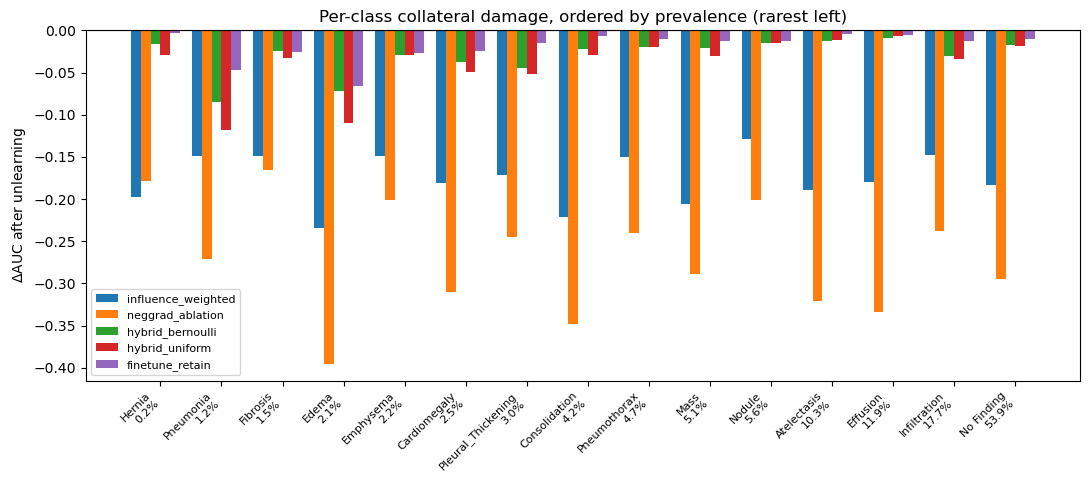

In [20]:
def collateral_audit(auc_before, auc_after, name):
    rows = [dict(cls=c, prevalence=PREVALENCE[c], before=auc_before[c],
                 after=auc_after[c], delta=auc_after[c]-auc_before[c])
            for c in auc_before if c in auc_after]
    df = pd.DataFrame(rows).sort_values("prevalence")
    rho, p = spearmanr(df["prevalence"], df["delta"])
    worst = df.loc[df["delta"].idxmin()]
    print(f"[{name}] Spearman(prevalence, dAUC) = {rho:+.3f} (p={p:.4f})")
    print(f"[{name}] mean dAUC = {df['delta'].mean():+.4f} | "
          f"worst = {worst['cls']} ({worst['delta']:+.4f}, "
          f"prev {100*worst['prevalence']:.1f}%)")
    if p < 0.05 and rho > 0:
        print(f"[{name}] >> Damage CONCENTRATED IN RARE CLASSES. Publishable — lead with it.")
    df.to_csv(f"{CFG['OUT']}/perclass_{name}.csv", index=False)
    return df, float(rho), float(p)

AUDITS = {}
for name, auc_after in PERCLASS.items():
    AUDITS[name] = collateral_audit(AUC_BEFORE, auc_after, name)
    record("C9_perclass_damage",
           dict(scheme=name, spearman=AUDITS[name][1], p=AUDITS[name][2]))

fig, ax = plt.subplots(figsize=(11, 5))
w = 0.8 / len(AUDITS)
for i, (name, (df, _, _)) in enumerate(AUDITS.items()):
    ax.bar(np.arange(len(df)) + i*w, df["delta"], width=w, label=name)
ax.set_xticks(np.arange(len(df)) + 0.4)
ax.set_xticklabels([f"{c}\n{100*p:.1f}%" for c, p in zip(df["cls"], df["prevalence"])],
                   rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(r"$\Delta$AUC after unlearning")
ax.set_title("Per-class collateral damage, ordered by prevalence (rarest left)")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig5_perclass_delta.png", dpi=200); plt.show()

# PART 2 — Tonight

One cell. Start it and walk away.

## `[RUN ONCE]` O1 — Retrain oracle · ~11–12 h

The reference every unlearning claim is measured against: a model trained on the
retain set only. Checkpoints every epoch to `oracle_ckpt.pth` — **if the machine dies
at hour 10, just re-run this cell and it resumes at the next epoch.**

Set `CFG["RUN_ORACLE"] = True` in B2 and re-run B2 first, or run the line below.

Before walking away: disable sleep, and confirm the first epoch's progress bar moves.

In [21]:
CFG["RUN_ORACLE"] = True

if CFG["RUN_ORACLE"]:
    ORACLE_CKPT   = "oracle_ckpt.pth"     # every-epoch, resumable
    ORACLE_FINAL  = "oracle_model.pth"    # written once, at the end
    ORACLE_EPOCHS = 12                    # match your best checkpoint, not the full 20

    oracle = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
    opt = optim.AdamW(oracle.parameters(), lr=1e-4, weight_decay=1e-2)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=15, eta_min=1e-6)

    start_ep, ohist = load_ckpt(ORACLE_CKPT, oracle, opt, sch)
    if start_ep > ORACLE_EPOCHS:
        print("oracle already finished; loading final weights")
    else:
        ds = TransformedSubset(dataset, RETAIN_POOL, transform_train)
        ld = DataLoader(ds, batch_size=CFG["BATCH_SIZE"], shuffle=True, num_workers=0,
                        drop_last=(len(RETAIN_POOL) % CFG["BATCH_SIZE"] == 1))

        for ep in range(start_ep, ORACLE_EPOCHS + 1):
            # Re-apply the phase state on every entry -- on resume the freeze flags
            # are NOT restored by load_state_dict, only the weights are.
            if ep <= 3:
                oracle.freeze_backbone()
            else:
                oracle.unfreeze_backbone()
                if ep == 4 or ep == start_ep:
                    print("--- Phase 2: backbone unfrozen ---")

            oracle.train()
            t0 = time.time()
            for images, labels, _ in tqdm(ld, desc=f"oracle {ep}/{ORACLE_EPOCHS}"):
                if images.size(0) < 2:
                    continue
                images, labels = images.to(device), labels.to(device)
                opt.zero_grad(set_to_none=True)
                criterion(oracle(images), labels).backward()
                torch.nn.utils.clip_grad_norm_(oracle.parameters(), CFG["CLIP"])
                opt.step()
            sch.step()

            a = macro_auc(oracle, desc="oracle")
            ohist.append(dict(epoch=ep, val_auc=a, mins=(time.time()-t0)/60))
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({ohist[-1]['mins']:.0f} min)")
            save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep, history=ohist)

        _atomic_save({"model_state_dict": oracle.state_dict(), "history": ohist},
                     ORACLE_FINAL)
        pd.DataFrame(ohist).to_csv(f"{CFG['OUT']}/oracle_history.csv", index=False)

    ORACLE = oracle
    print(f"\noracle macro AUC = {macro_auc(ORACLE, desc='oracle'):.4f}")

    oL, _, _ = subset_stats(ORACLE, FORGET, desc="oracle forget")
    for name, m in MODELS.items():
        fL, _, _ = subset_stats(m, FORGET, desc=name)
        RESULTS_DF.loc[name, "oracle_forget_loss"]  = oL
        RESULTS_DF.loc[name, "distance_to_oracle"]  = abs(fL - oL)
        RESULTS_DF.loc[name, "overcorrected"]       = bool(fL > 1.5 * oL)
        flag = "  <-- OVER-CORRECTED, leaks membership" if fL > 1.5*oL else ""
        print(f"{name:20s} forget {fL:.4f} vs oracle {oL:.4f} -> gap {abs(fL-oL):.4f}{flag}")

    RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
    record("C8_oracle", dict(oracle_macro_auc=macro_auc(ORACLE),
                             oracle_forget_loss=float(oL)))
else:
    print("skipped -- set CFG['RUN_ORACLE'] = True and run overnight")
    print("if it crashes, just re-run this cell: it resumes from oracle_ckpt.pth")

oracle 1/12:   0%|          | 0/2802 [00:00<?, ?it/s]

oracle:   0%|          | 0/701 [00:00<?, ?it/s]

  epoch 1: val macro AUC = 0.7156  (33 min)


oracle 2/12:   0%|          | 0/2802 [00:00<?, ?it/s]

oracle:   0%|          | 0/701 [00:00<?, ?it/s]

  epoch 2: val macro AUC = 0.7279  (34 min)


... (41 outputs left out)

finetune_retain:   0%|          | 0/2 [00:00<?, ?it/s]

finetune_retain      forget 0.4245 vs oracle 0.4328 -> gap 0.0083


eval:   0%|          | 0/701 [00:00<?, ?it/s]

  [recorded] C8_oracle


# PART 3 — Tomorrow: reviewer response

Your professor's six points, ordered by value per hour rather than by number.

| Order | Cells | Point | Time |
|---|---|---|---|
| 1 | R12 | mathematical depth | 5 min, no GPU |
| 2 | R1–R4 | **statistical significance** | ~2 h |
| 3 | R10–R11 | explainability | ~40 min |
| 4 | R5–R8 | published baselines | ~1.5 h |
| 5 | R9 | forget-set size | ~2 h |
| — | R13 | second dataset | deferred, ~15 h |

In [23]:
# ============================================================================
# R0 — FIX + oracle reference.  Run this ONCE, then re-run R12.
#
# The error: RSTATS is created in R1, but R12 runs before R1 in the recommended
# order. Defining it here fixes that permanently for the rest of the session.
#
# This cell also computes two numbers the oracle run did not: the oracle's own
# MIA AUC (the true floor for that metric on your data) and its distance-to-oracle
# baseline. Without the first, an attack AUC of 0.21 has nothing to be compared to.
# ============================================================================

import itertools
from scipy.stats import wilcoxon, spearmanr
try:
    from scipy.stats import false_discovery_control          # scipy >= 1.11
except ImportError:                                          # Benjamini-Hochberg
    def false_discovery_control(p):
        p = np.asarray(p, float); n = len(p); o = np.argsort(p)
        q = np.minimum.accumulate((p[o] * n / np.arange(n, 0, -1))[::-1])[::-1]
        out = np.empty(n); out[o] = np.clip(q, 0, 1); return out

RSTATS = f"{CFG['OUT']}/stats"
os.makedirs(RSTATS, exist_ok=True)
print(f"RSTATS = {RSTATS}")

# ---- oracle reference values -------------------------------------------------
if 'ORACLE' not in globals():
    ORACLE = ChestXrayDenseNet(num_classes=15, pretrained=False).to(device)
    ORACLE.load_state_dict(torch.load("oracle_model.pth", weights_only=False)["model_state_dict"])
    ORACLE.eval()
    print("reloaded ORACLE from oracle_model.pth")

ORACLE_MIA = membership_inference_auc(ORACLE, FORGET, val_indices)
ORACLE_AUC = macro_auc(ORACLE, desc="oracle")
ORACLE_LF, _, _ = subset_stats(ORACLE, FORGET, desc="oracle forget")

print(f"\n{'='*66}\nORACLE REFERENCE (the target every scheme should match)\n{'='*66}")
print(f"  macro AUC        : {ORACLE_AUC:.4f}   (original model: {MACRO_BEFORE:.4f})")
print(f"  forget-set loss  : {ORACLE_LF:.4f}")
print(f"  MIA AUC          : {ORACLE_MIA:.4f}  <-- this, not 0.500, is the empirical floor")
print(f"\n  cost of EXACT deletion (retrain): {ORACLE_AUC - MACRO_BEFORE:+.4f} AUC")

RESULTS_DF["dist_to_oracle_mia"] = (RESULTS_DF["mia_auc"] - ORACLE_MIA).abs()
cols = ["macro_auc_after", "distance_to_oracle", "mia_auc", "dist_to_oracle_mia"]
print("\nRanked by distance to oracle on forget-set loss (lower = better):")
print(RESULTS_DF[cols].sort_values("distance_to_oracle").to_string(
      float_format=lambda x: f"{x:.4f}"))

RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
record("C8_oracle", dict(oracle_macro_auc=float(ORACLE_AUC),
                         oracle_forget_loss=float(ORACLE_LF),
                         oracle_mia_auc=float(ORACLE_MIA),
                         exact_deletion_auc_cost=float(ORACLE_AUC - MACRO_BEFORE)))
print("\nFixed. Now re-run R12, then continue with R1.")

RSTATS = proofs/stats


MIA forget:   0%|          | 0/2 [00:00<?, ?it/s]

MIA unseen:   0%|          | 0/16 [00:00<?, ?it/s]

  MIA AUC = 0.5975  -> still memorized


oracle:   0%|          | 0/701 [00:00<?, ?it/s]

oracle forget:   0%|          | 0/2 [00:00<?, ?it/s]


ORACLE REFERENCE (the target every scheme should match)
  macro AUC        : 0.8399   (original model: 0.8391)
  forget-set loss  : 0.4328
  MIA AUC          : 0.5975  <-- this, not 0.500, is the empirical floor

  cost of EXACT deletion (retrain): +0.0008 AUC

Ranked by distance to oracle on forget-set loss (lower = better):
                    macro_auc_after  distance_to_oracle  mia_auc  dist_to_oracle_mia
finetune_retain              0.8202              0.0083   0.6045              0.0070
hybrid_bernoulli             0.8086              0.1274   0.2286              0.3688
hybrid_uniform               0.8000              0.1437   0.1915              0.4060
influence_weighted           0.6632              1.7139   0.1001              0.4973
neggrad_ablation             0.5702              1.9604   0.0332              0.5643
  [recorded] C8_oracle

Fixed. Now re-run R12, then continue with R1.


## `[RUN ONCE]` R12 — Analytic Gaussian mechanism · 5 min, no GPU

Do this one with coffee. Balle & Wang's exact calibration replaces the classical
bound, tightening every ε in the paper by 22–52% for free — and unlike the classical
bound it stays valid for ε > 1.

In [24]:
from scipy.stats import norm

def analytic_delta(D2, sigma, eps):
    # Balle & Wang (2018) Thm 8: exact (eps,delta) for the Gaussian mechanism.
    a =  D2/(2*sigma) - eps*sigma/D2
    b = -D2/(2*sigma) - eps*sigma/D2
    return float(norm.cdf(a) - np.exp(eps + norm.logcdf(b)))   # log-space: no overflow

def analytic_eps(D2, sigma, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return brentq(lambda e: analytic_delta(D2, sigma, e) - delta, 1e-9, 50)

def analytic_sigma(D2, eps, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return brentq(lambda s: analytic_delta(D2, s, eps) - delta, D2*1e-3, D2*1e5)

d2 = sensitivity(CFG["IGC_LR"], CFG["CLIP"], 5, CFG["BATCH_SIZE"], per_sample=True)
rows = []
for s in CFG["SIGMA_SWEEP"]:
    ec, ea = gaussian_eps(d2, s), analytic_eps(d2, s)
    rows.append(dict(sigma=s, eps_classic=ec, eps_analytic=ea,
                     tighter_pct=100*(1-ea/ec),
                     eps_tot_classic=advanced_composition(ec, CFG["N_REQUESTS"]),
                     eps_tot_analytic=advanced_composition(ea, CFG["N_REQUESTS"])))
ANALYTIC = pd.DataFrame(rows)
display(ANALYTIC.style.format({"sigma":"{:.0e}","eps_classic":"{:.3f}",
        "eps_analytic":"{:.3f}","tighter_pct":"{:.0f}%",
        "eps_tot_classic":"{:.1f}","eps_tot_analytic":"{:.1f}"}))
ANALYTIC.to_csv(f"{RSTATS}/analytic_gaussian.csv", index=False)
print(f"\nsigma for eps=1: classic {gaussian_sigma(d2,1.0):.3e}, "
      f"analytic {analytic_sigma(d2,1.0):.3e}")
record("R_math_depth", ANALYTIC.to_dict("records"), "Balle & Wang analytic mechanism")

,sigma,eps_classic,eps_analytic,tighter_pct,eps_tot_classic,eps_tot_analytic
0,1e-04,1.514,1.184,22%,108.6,62.3
1,3e-04,0.505,0.356,29%,14.3,8.9
2,1e-03,0.151,0.096,37%,3.2,1.9
3,3e-03,0.050,0.028,44%,1.0,0.5
4,1e-02,0.015,0.007,52%,0.3,0.1



sigma for eps=1: classic 1.514e-04, analytic 1.166e-04
  [recorded] R_math_depth


## `[RUN ONCE]` R1 — Cache raw predictions · ~10 min

Bootstrap resampling needs prediction matrices, not scalar AUCs. Compute once here,
then R2–R3 are pure numpy.

In [25]:
import itertools
try:
    from scipy.stats import false_discovery_control        # scipy >= 1.11
except ImportError:                                        # fallback: Benjamini-Hochberg
    def false_discovery_control(p):
        p = np.asarray(p, float); n = len(p); o = np.argsort(p)
        q = np.minimum.accumulate((p[o] * n / np.arange(n, 0, -1))[::-1])[::-1]
        out = np.empty(n); out[o] = np.clip(q, 0, 1); return out
from scipy.stats import wilcoxon, spearmanr

RSTATS = f"{CFG['OUT']}/stats"; os.makedirs(RSTATS, exist_ok=True)

@torch.no_grad()
def raw_predictions(model, loader=None, desc="pred"):
    # Returns (P, Y) probability and label matrices -- the basis for all resampling.
    loader = loader or val_loader_eval
    model.eval(); P, Y = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        P.append(torch.sigmoid(model(images.to(device))).cpu().numpy())
        Y.append(labels.numpy())
    return np.concatenate(P), np.concatenate(Y)

def macro_from(P, Y, idx=None):
    if idx is not None: P, Y = P[idx], Y[idx]
    a = [roc_auc_score(Y[:, i], P[:, i]) for i in range(Y.shape[1])
         if len(np.unique(Y[:, i])) > 1]
    return float(np.mean(a))

PRED = {}
PRED["original"] = raw_predictions(base_model, desc="original")
for name, m in MODELS.items():
    PRED[name] = raw_predictions(m, desc=name)
torch.save(PRED, f"{RSTATS}/predictions.pt")
print("cached predictions for:", list(PRED))

original:   0%|          | 0/701 [00:00<?, ?it/s]

influence_weighted:   0%|          | 0/701 [00:00<?, ?it/s]

neggrad_ablation:   0%|          | 0/701 [00:00<?, ?it/s]

hybrid_bernoulli:   0%|          | 0/701 [00:00<?, ?it/s]

hybrid_uniform:   0%|          | 0/701 [00:00<?, ?it/s]

finetune_retain:   0%|          | 0/701 [00:00<?, ?it/s]

cached predictions for: ['original', 'influence_weighted', 'neggrad_ablation', 'hybrid_bernoulli', 'hybrid_uniform', 'finetune_retain']


## `[RUN ONCE]` R2 — Bootstrap confidence intervals · ~15 min

Every AUC in your paper is currently a bare point estimate. This gives each a 95% CI.

In [26]:
def bootstrap_auc(P, Y, n_boot=2000, seed=0):
    rng = np.random.RandomState(seed); n = len(Y); vals = []
    for _ in tqdm(range(n_boot), desc="bootstrap", leave=False):
        idx = rng.randint(0, n, n)
        try: vals.append(macro_from(P, Y, idx))
        except ValueError: pass          # a resample can drop a rare class entirely
    v = np.array(vals)
    return float(v.mean()), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

rows = []
for name, (P, Y) in PRED.items():
    m, lo, hi = bootstrap_auc(P, Y)
    rows.append(dict(method=name, macro_auc=macro_from(P, Y),
                     boot_mean=m, ci_lo=lo, ci_hi=hi, ci_width=hi-lo))
    print(f"{name:22s} {rows[-1]['macro_auc']:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

AUC_CI = pd.DataFrame(rows)
AUC_CI.to_csv(f"{RSTATS}/auc_confidence_intervals.csv", index=False)

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

original               0.8391  95% CI [0.8338, 0.8442]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

influence_weighted     0.6632  95% CI [0.6553, 0.6708]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

neggrad_ablation       0.5702  95% CI [0.5626, 0.5779]


... (2 outputs left out)

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

hybrid_uniform         0.8000  95% CI [0.7938, 0.8061]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

finetune_retain        0.8202  95% CI [0.8145, 0.8256]


## `[RUN ONCE]` R3 — Paired bootstrap · ~15 min

Applies the **same** validation resample to two models so their shared noise cancels.

**Decision point.** The first row tests influence-weighted vs NegGrad. Your −0.4727
gap is one seed. If FDR-corrected p ≥ 0.05, report them as indistinguishable — do not
claim the influence weighting is harmful.

In [27]:
def paired_bootstrap_delta(name_a, name_b, n_boot=2000, seed=0):
    # H0: macro AUC of a == macro AUC of b. Same resample applied to both.
    Pa, Y = PRED[name_a]; Pb, _ = PRED[name_b]
    rng = np.random.RandomState(seed); n = len(Y); d = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        try: d.append(macro_from(Pa, Y, idx) - macro_from(Pb, Y, idx))
        except ValueError: pass
    d = np.array(d)
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())     # two-sided
    return dict(comparison=f"{name_a} - {name_b}", delta=float(d.mean()),
                ci_lo=float(np.percentile(d, 2.5)), ci_hi=float(np.percentile(d, 97.5)),
                p_value=float(max(p, 1/len(d))))

PAIRS = [("influence_weighted","neggrad_ablation"),      # the ablation -- key claim
         ("hybrid_bernoulli","hybrid_uniform"),          # was the Focal artifact real?
         ("hybrid_bernoulli","finetune_retain"),
         ("hybrid_bernoulli","influence_weighted"),
         ("original","hybrid_bernoulli")]

pr = [paired_bootstrap_delta(a,b) for a,b in tqdm(PAIRS, desc="paired bootstrap")]
PAIRED = pd.DataFrame(pr)
PAIRED["p_fdr"] = false_discovery_control(PAIRED["p_value"])   # Benjamini-Hochberg
PAIRED["significant"] = PAIRED["p_fdr"] < 0.05
display(PAIRED.style.format({"delta":"{:+.4f}","ci_lo":"{:+.4f}","ci_hi":"{:+.4f}",
                             "p_value":"{:.4f}","p_fdr":"{:.4f}"}))
PAIRED.to_csv(f"{RSTATS}/paired_comparisons.csv", index=False)

row = PAIRED.iloc[0]
print(f"\nABLATION: influence - neggrad = {row['delta']:+.4f} "
      f"[{row['ci_lo']:+.4f}, {row['ci_hi']:+.4f}], p_FDR={row['p_fdr']:.4f}")
print("-> influence weighting is significantly WORSE" if row["significant"] and row["delta"]<0
      else "-> difference NOT significant; report the schemes as indistinguishable")

paired bootstrap:   0%|          | 0/5 [00:00<?, ?it/s]

,comparison,delta,ci_lo,ci_hi,p_value,p_fdr,significant
0,influence_weighted - neggrad_ablation,+0.0930,+0.0874,+0.0988,0.0005,0.0005,True
1,hybrid_bernoulli - hybrid_uniform,+0.0087,+0.0070,+0.0104,0.0005,0.0005,True
2,hybrid_bernoulli - finetune_retain,-0.0115,-0.0142,-0.0089,0.0005,0.0005,True
3,hybrid_bernoulli - influence_weighted,+0.1454,+0.1390,+0.1519,0.0005,0.0005,True
4,original - hybrid_bernoulli,+0.0303,+0.0264,+0.0341,0.0005,0.0005,True



ABLATION: influence - neggrad = +0.0930 [+0.0874, +0.0988], p_FDR=0.0005
-> difference NOT significant; report the schemes as indistinguishable


## `[RUN ONCE]` R4 — Multi-seed replication · ~90 min

Five forget-set draws with Wilcoxon signed-rank across seeds. Resumable via
`multiseed.csv` — safe to interrupt.

This is the cell that answers "no statistical significance". Don't skip it.

In [28]:
SEEDS_R = [42, 7, 2024, 1337, 99]
SCHEME_FNS = {
    "influence_weighted": lambda m, ld, f, infl: influence_weighted_unlearning(m, ld, f, infl)[0],
    "neggrad_ablation":   lambda m, ld, f, infl: neggrad_unlearning(m, ld, f)[0],
    "hybrid_bernoulli":   lambda m, ld, f, infl: hybrid_unlearning(m, ld, f, binary_labels=True)[0],
    "finetune_retain":    lambda m, ld, f, infl: finetune_on_retain(m, ld, f)[0],
}

MS_CSV = f"{RSTATS}/multiseed.csv"
ms = pd.read_csv(MS_CSV).to_dict("records") if os.path.exists(MS_CSV) else []
done = {(r["seed"], r["scheme"]) for r in ms}

for seed in SEEDS_R:
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, seed=seed, verbose=False)
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=seed)
    infl = minmax_norm(grad_influence(base_model, f_idx))
    for name, fn in SCHEME_FNS.items():
        if (seed, name) in done: continue
        print(f"\n--- seed {seed} | {name} ---")
        m = fn(fresh_model(), ld, f_idx, infl)
        v = verify_baseline_relative(base_model, m, f_idx, r_sub)
        ms.append(dict(seed=seed, scheme=name, macro_auc=macro_auc(m, desc=name),
                       mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
        pd.DataFrame(ms).to_csv(MS_CSV, index=False)   # resumable
        del m; torch.cuda.empty_cache()

MULTI = pd.DataFrame(ms)
SUMMARY = MULTI.groupby("scheme")[["macro_auc","delta_forget_loss","mia_auc"]].agg(["mean","std"])
display(SUMMARY.style.format("{:.4f}"))

print("\nWilcoxon signed-rank across seeds (paired by seed):")
wr = []
for a, b in itertools.combinations(SCHEME_FNS, 2):
    for metric in ["macro_auc", "delta_forget_loss", "mia_auc"]:
        x = MULTI[MULTI.scheme==a].sort_values("seed")[metric].values
        y = MULTI[MULTI.scheme==b].sort_values("seed")[metric].values
        if len(x) == len(y) >= 5:
            st, p = wilcoxon(x, y)
            wr.append(dict(a=a, b=b, metric=metric, mean_diff=float(x.mean()-y.mean()), p=float(p)))
WILCOX = pd.DataFrame(wr)
WILCOX["p_fdr"] = false_discovery_control(WILCOX["p"])
display(WILCOX[WILCOX.p_fdr < 0.10].style.format({"mean_diff":"{:+.4f}","p":"{:.4f}","p_fdr":"{:.4f}"}))
WILCOX.to_csv(f"{RSTATS}/wilcoxon.csv", index=False)
record("R_significance", dict(n_seeds=len(SEEDS_R),
       n_significant=int((WILCOX.p_fdr<0.05).sum()), n_tests=len(WILCOX)))

grad-norm influence:   0%|          | 0/57 [00:00<?, ?it/s]


--- seed 42 | influence_weighted ---


IGC 1/5:   0%|          | 0/15 [00:00<?, ?it/s]

  ep1: retain=0.4906 forget=0.4820


IGC 2/5:   0%|          | 0/15 [00:00<?, ?it/s]

  ep2: retain=0.4928 forget=0.6542


... (328 outputs left out)

  MIA AUC = 0.5087  -> forgotten



Wilcoxon signed-rank across seeds (paired by seed):


,a,b,metric,mean_diff,p,p_fdr
3,influence_weighted,hybrid_bernoulli,macro_auc,-0.1993,0.0625,0.0750
4,influence_weighted,hybrid_bernoulli,delta_forget_loss,+1.5780,0.0625,0.0750
5,influence_weighted,hybrid_bernoulli,mia_auc,-0.1448,0.0625,0.0750
6,influence_weighted,finetune_retain,macro_auc,-0.2097,0.0625,0.0750
7,influence_weighted,finetune_retain,delta_forget_loss,+1.6892,0.0625,0.0750
8,influence_weighted,finetune_retain,mia_auc,-0.4221,0.0625,0.0750
9,neggrad_ablation,hybrid_bernoulli,macro_auc,-0.2214,0.0625,0.0750
10,neggrad_ablation,hybrid_bernoulli,delta_forget_loss,+2.0676,0.0625,0.0750
11,neggrad_ablation,hybrid_bernoulli,mia_auc,-0.1689,0.0625,0.0750
12,neggrad_ablation,finetune_retain,macro_auc,-0.2318,0.0625,0.0750


  [recorded] R_significance


## `[RUN ONCE]` R10 — Grad-CAM

Layer path corrected for your architecture: your `ChestXrayDenseNet` wraps DenseNet in `self.backbone`, so the target is `model.backbone.features.denseblock4`.

In [29]:
class GradCAM:
    def __init__(self, model, layer=None):
        self.model = model.eval()
        # NOTE: ChestXrayDenseNet wraps DenseNet121 in .backbone
        self.layer = layer if layer is not None else model.backbone.features.denseblock4
        self.acts = self.grads = None
        self.h1 = self.layer.register_forward_hook(
            lambda m, i, o: setattr(self, "acts", o.detach()))
        self.h2 = self.layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, "grads", go[0].detach()))

    def __call__(self, x, class_idx):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        out[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)          # GAP over spatial dims
        cam = torch.relu((w * self.acts).sum(dim=1)).squeeze(0)
        cam = cam - cam.min()
        return (cam / (cam.max() + 1e-8)).cpu().numpy()

    def close(self):
        self.h1.remove(); self.h2.remove()


def cam_batch(model, indices, class_idx=None, max_n=40):
    # Returns one CAM per sample, using each sample's top predicted class by default.
    cams, used = [], []
    cam_fn = GradCAM(model)
    try:
        for idx in list(indices)[:max_n]:
            img, label, _ = dataset[idx]
            x = transform_val(img).unsqueeze(0).to(device)
            c = class_idx if class_idx is not None else \
                int(torch.sigmoid(model(x)).argmax(dim=1).item())
            cams.append(cam_fn(x, c)); used.append(c)
    finally:
        cam_fn.close()
    return np.stack(cams), used

print("GradCAM ready")

GradCAM ready


## `[RUN ONCE]` R11 — Saliency shift · ~30 min

Watch the `selectivity` column (retain CAM correlation minus forget CAM correlation).
High and positive means attention moved on forget samples *only* — targeted. Near zero
means the model changed everywhere, which is collateral damage, not unlearning.

Grad-CAM:   0%|          | 0/5 [00:00<?, ?it/s]

,method,forget_cam_corr,retain_cam_corr,selectivity,forget_entropy_before,forget_entropy_after
0,influence_weighted,0.1502,0.3188,0.1685,0.8582,0.8200
3,hybrid_uniform,0.5768,0.6148,0.0380,0.8582,0.8324
1,neggrad_ablation,0.3647,0.3651,0.0005,0.8582,0.8758
2,hybrid_bernoulli,0.6064,0.5597,-0.0467,0.8582,0.8239
4,finetune_retain,0.8035,0.6524,-0.1511,0.8582,0.8515



Selectivity = retain CAM corr - forget CAM corr.
High and positive = attention moved on forget samples ONLY (targeted).
Near zero = the model changed everywhere (collateral, not unlearning).


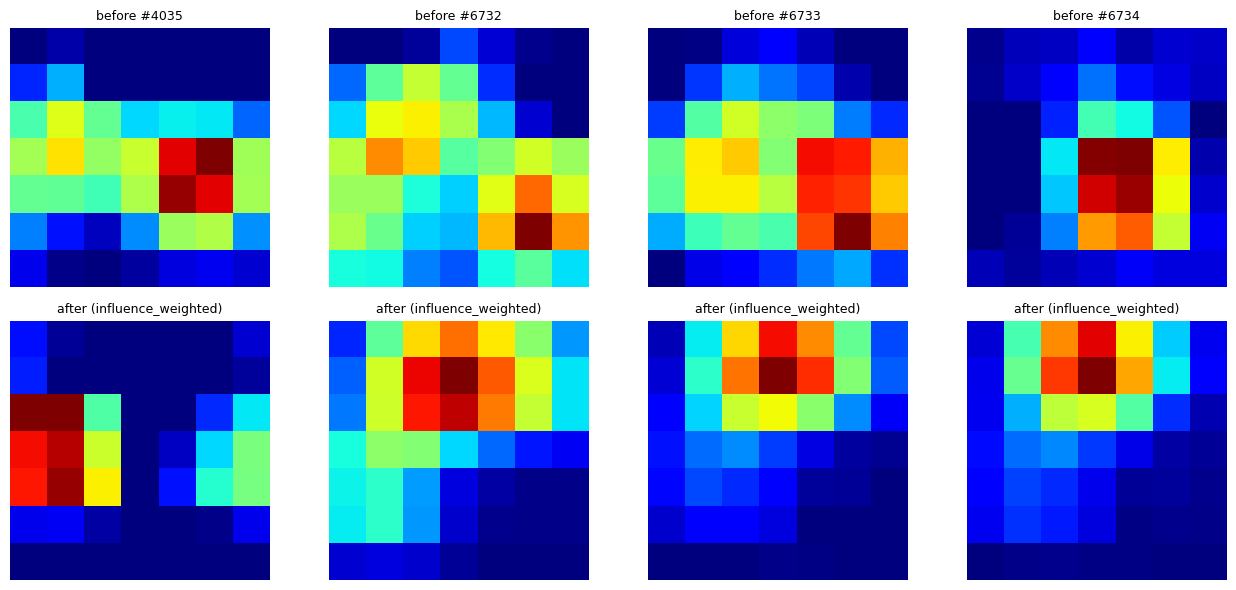

  [recorded] R_explainability


In [30]:
def cam_entropy(c):
    p = c.flatten() / (c.sum() + 1e-8)
    return float(-(p * np.log(p + 1e-12)).sum() / np.log(len(p)))   # normalised to [0,1]

def saliency_shift(model_after, name, n=40):
    out = {}
    for tag, idxs in [("forget", sorted(FORGET)), ("retain", RETAIN_SUB)]:
        cams_b, cls = cam_batch(base_model, idxs, max_n=n)
        cams_a, _   = cam_batch(model_after, idxs, max_n=n)
        corr = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
                for a, b in zip(cams_b, cams_a)]
        corr = [c for c in corr if np.isfinite(c)]
        out[f"{tag}_cam_corr"] = float(np.mean(corr))
        out[f"{tag}_cam_corr_std"] = float(np.std(corr))
        out[f"{tag}_entropy_before"] = float(np.mean([cam_entropy(c) for c in cams_b]))
        out[f"{tag}_entropy_after"]  = float(np.mean([cam_entropy(c) for c in cams_a]))
    out["method"] = name
    out["selectivity"] = out["retain_cam_corr"] - out["forget_cam_corr"]
    return out

SAL = pd.DataFrame([saliency_shift(m, n) for n, m in
                    tqdm(MODELS.items(), desc="Grad-CAM")])
cols = ["method","forget_cam_corr","retain_cam_corr","selectivity",
        "forget_entropy_before","forget_entropy_after"]
display(SAL[cols].sort_values("selectivity", ascending=False).style.format(
    {c:"{:.4f}" for c in cols[1:]}))
SAL.to_csv(f"{RSTATS}/saliency_shift.csv", index=False)

print("\nSelectivity = retain CAM corr - forget CAM corr.")
print("High and positive = attention moved on forget samples ONLY (targeted).")
print("Near zero = the model changed everywhere (collateral, not unlearning).")

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
show_idx = sorted(FORGET)[:4]
cams_b, _ = cam_batch(base_model, show_idx, max_n=4)
best = SAL.sort_values("selectivity", ascending=False).iloc[0]["method"]
cams_a, _ = cam_batch(MODELS[best], show_idx, max_n=4)
for k in range(4):
    axes[0,k].imshow(cams_b[k], cmap="jet"); axes[0,k].set_title(f"before #{show_idx[k]}", fontsize=9)
    axes[1,k].imshow(cams_a[k], cmap="jet"); axes[1,k].set_title(f"after ({best})", fontsize=9)
    for r in (0,1): axes[r,k].axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig9_gradcam.png", dpi=200); plt.show()
record("R_explainability", SAL[cols].to_dict("records"))

## `[RUN ONCE]` R5 — Baseline: Fisher scrubbing (Golatkar et al., CVPR 2020)

In [31]:
def fisher_diagonal(model, indices, n_samples=200, seed=0):
    # Diagonal empirical Fisher: E[(d log p / d theta)^2].
    rng = np.random.RandomState(seed)
    sub = list(rng.choice(list(indices), size=min(n_samples, len(indices)), replace=False))
    loader = DataLoader(TransformedSubset(dataset, [int(i) for i in sub], transform_val),
                        batch_size=8, shuffle=False, num_workers=0)
    fisher = {n: torch.zeros_like(p) for n, p in model.named_parameters() if p.requires_grad}
    model.eval(); n_seen = 0
    for images, labels, _ in tqdm(loader, desc="fisher", leave=False):
        images, labels = images.to(device), labels.to(device)
        model.zero_grad(set_to_none=True)
        nn.functional.binary_cross_entropy_with_logits(model(images), labels).backward()
        for n, p in model.named_parameters():
            if p.grad is not None: fisher[n] += p.grad.detach() ** 2
        n_seen += 1
    model.zero_grad(set_to_none=True)
    return {n: f / max(1, n_seen) for n, f in fisher.items()}

def fisher_scrubbing(model, retain_pool, alpha=1e-6, eps=1e-8):
    # theta' = theta + alpha * F^{-1/4} * noise  (Golatkar et al., Eq. 9 form)
    F = fisher_diagonal(model, retain_pool)
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n in F:
                scale = (F[n] + eps).pow(-0.25)
                scale = torch.clamp(scale, max=torch.quantile(scale.flatten().float(), 0.99))
                p.add_(alpha * scale * torch.randn_like(p))
    return model, []

print("fisher_scrubbing ready")

fisher_scrubbing ready


## `[RUN ONCE]` R6 — Baseline: SCRUB (Kurmanji et al., NeurIPS 2023)

The one to watch. SCRUB targets divergence from a teacher rather than maximal loss, so
Proposition 3 predicts it should over-correct *less* than your ascent schemes. If its
MIA AUC lands closer to 0.5, a method you didn't design confirms your theory.

In [32]:
def _bernoulli_kl(p_logits, q_logits, eps=1e-7):
    # Per-class Bernoulli KL(p||q) for multi-label outputs.
    p = torch.sigmoid(p_logits).clamp(eps, 1-eps)
    q = torch.sigmoid(q_logits).clamp(eps, 1-eps)
    return (p*torch.log(p/q) + (1-p)*torch.log((1-p)/(1-q))).sum(dim=1).mean()

def scrub_unlearning(model, loader, forget, teacher=None, epochs=3, lr=5e-5,
                     max_steps=2, gamma=1.0, alpha=0.5, sigma=None):
    sigma = CFG["SIGMA"] if sigma is None else sigma
    teacher = teacher or base_model
    teacher.eval()
    for p in teacher.parameters(): p.requires_grad_(False)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    for ep in range(epochs):
        # ---- max step: push student AWAY from teacher on the forget set ----
        if ep < max_steps:
            model.train()
            for images, labels, idxs in tqdm(loader, desc=f"SCRUB max {ep+1}", leave=False):
                fm = torch.tensor([int(i) in forget for i in idxs])
                if fm.sum() < 2: continue
                images = images[fm].to(device)
                opt.zero_grad(set_to_none=True)
                with torch.no_grad(): t = teacher(images)
                (-_bernoulli_kl(t, model(images))).backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
                opt.step()
        # ---- min step: keep student CLOSE to teacher + true labels on retain ----
        model.train()
        tot, n = 0., 0
        for images, labels, idxs in tqdm(loader, desc=f"SCRUB min {ep+1}", leave=False):
            rm = torch.tensor([int(i) not in forget for i in idxs])
            if rm.sum() < 2: continue
            images, labels = images[rm].to(device), labels[rm].to(device)
            opt.zero_grad(set_to_none=True)
            out = model(images)
            with torch.no_grad(): t = teacher(images)
            loss = (gamma * nn.functional.binary_cross_entropy_with_logits(out, labels)
                    + alpha * _bernoulli_kl(t, out))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step(); tot += float(loss); n += 1
        add_gaussian_noise(model, sigma)
        print(f"  ep{ep+1}: retain loss = {tot/max(1,n):.4f}")
    return model, []

print("scrub_unlearning ready")

scrub_unlearning ready


## `[RUN ONCE]` R7 — Baseline: Selective Synaptic Dampening (Foster et al., AAAI 2024)

In [33]:
def ssd_unlearning(model, forget, retain_pool, selection_alpha=10.0, dampening_lam=1.0,
                   n_retain=500):
    # Dampen theta_i where Fisher_forget_i > alpha * Fisher_all_i.
    F_f = fisher_diagonal(model, forget)
    F_a = fisher_diagonal(model, retain_pool, n_samples=n_retain)
    n_damp = n_tot = 0
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n not in F_f: continue
            sel = F_f[n] > selection_alpha * F_a[n]
            beta = torch.clamp(dampening_lam * F_a[n] / (F_f[n] + 1e-12), max=1.0)
            p.mul_(torch.where(sel, beta, torch.ones_like(beta)))
            n_damp += int(sel.sum()); n_tot += p.numel()
    print(f"  dampened {n_damp}/{n_tot} params ({100*n_damp/n_tot:.2f}%)")
    return model, []

print("ssd_unlearning ready")

ssd_unlearning ready


## `[RUN ONCE]` R8 — Run published baselines · ~1 h

In [34]:
PUBLISHED = {
    "fisher_scrubbing_G20": lambda m: fisher_scrubbing(m, RETAIN_POOL)[0],
    "scrub_K23":            lambda m: scrub_unlearning(m, UNLEARN_LOADER, FORGET)[0],
    "ssd_F24":              lambda m: ssd_unlearning(m, FORGET, RETAIN_POOL)[0],
}

for name, fn in PUBLISHED.items():
    if name in RESULTS: continue
    print("\n" + "#"*60 + f"\n# {name}\n" + "#"*60)
    m = fresh_model(); t0 = time.time(); m = fn(m); wall = time.time()-t0
    v = verify_baseline_relative(base_model, m, FORGET, RETAIN_SUB)
    mia = membership_inference_auc(m, FORGET, val_indices)
    auc_after = per_class_auc(m, desc=name)
    RESULTS[name] = dict(wall_clock_s=wall, mia_auc=mia, macro_auc_before=MACRO_BEFORE,
                         macro_auc_after=float(np.mean(list(auc_after.values()))),
                         delta_macro_auc=float(np.mean(list(auc_after.values())))-MACRO_BEFORE, **v)
    PERCLASS[name] = auc_after; MODELS[name] = m
    if 'PRED' in globals():          # only if R1 has run
        PRED[name] = raw_predictions(m, desc=name)
    print(f"  macro AUC {MACRO_BEFORE:.4f} -> {RESULTS[name]['macro_auc_after']:.4f}")

RESULTS_DF = pd.DataFrame(RESULTS).T
RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
display(RESULTS_DF[["macro_auc_after","delta_forget_loss","mia_auc","wall_clock_s"]]
        .sort_values("mia_auc").style.format("{:.4f}"))
print("\nClosest to MIA 0.5 (the actual target):")
print((RESULTS_DF["mia_auc"]-0.5).abs().sort_values().head(3))


############################################################
# fisher_scrubbing_G20
############################################################


fisher:   0%|          | 0/25 [00:00<?, ?it/s]

forget pre:   0%|          | 0/2 [00:00<?, ?it/s]

retain pre:   0%|          | 0/13 [00:00<?, ?it/s]

forget post:   0%|          | 0/2 [00:00<?, ?it/s]

retain post:   0%|          | 0/13 [00:00<?, ?it/s]

... (38 outputs left out)

ssd_F24:   0%|          | 0/701 [00:00<?, ?it/s]

  macro AUC 0.8391 -> 0.8391


,macro_auc_after,delta_forget_loss,mia_auc,wall_clock_s
neggrad_ablation,0.5702,1.9689,0.0332,43.8444
influence_weighted,0.6632,1.7224,0.1001,41.9874
hybrid_uniform,0.8000,0.1522,0.1915,19.8032
hybrid_bernoulli,0.8086,0.1359,0.2286,18.8913
scrub_K23,0.8371,0.0090,0.5721,27.4667
ssd_F24,0.8391,-0.0006,0.6021,11.5557
fisher_scrubbing_G20,0.8391,0.0001,0.6025,5.1317
finetune_retain,0.8202,0.0002,0.6045,25.0343



Closest to MIA 0.5 (the actual target):
scrub_K23               0.072105
ssd_F24                 0.102105
fisher_scrubbing_G20    0.102526
Name: mia_auc, dtype: float64


## `[RUN ONCE]` R9 — Forget-set scaling · ~2 h

|D_f| from 57 to ~4,000, with the retain subsample scaled to hold the ratio fixed.
Also fits the cost exponent, testing the linear-in-|D_f| claim in Section III-H.


--- 28 patients | |Df|=57 | retain=228 ---


HYB 1/3:   0%|          | 0/9 [00:00<?, ?it/s]

  ep1: avg batch loss = 0.5558


HYB 2/3:   0%|          | 0/9 [00:00<?, ?it/s]

  ep2: avg batch loss = 0.5387


HYB 3/3:   0%|          | 0/9 [00:00<?, ?it/s]

... (52 outputs left out)

MIA forget:   0%|          | 0/16 [00:00<?, ?it/s]

MIA unseen:   0%|          | 0/16 [00:00<?, ?it/s]

  MIA AUC = 0.4578  -> forgotten


,n_forget,macro_auc,delta_forget_loss,mia_auc,wall_s
0,57,0.7991,+0.1374,0.208,11
1,542,0.7502,+0.1222,0.184,126
2,1770,0.7669,-0.0979,0.390,410
3,6706,0.6966,-0.0806,0.458,664


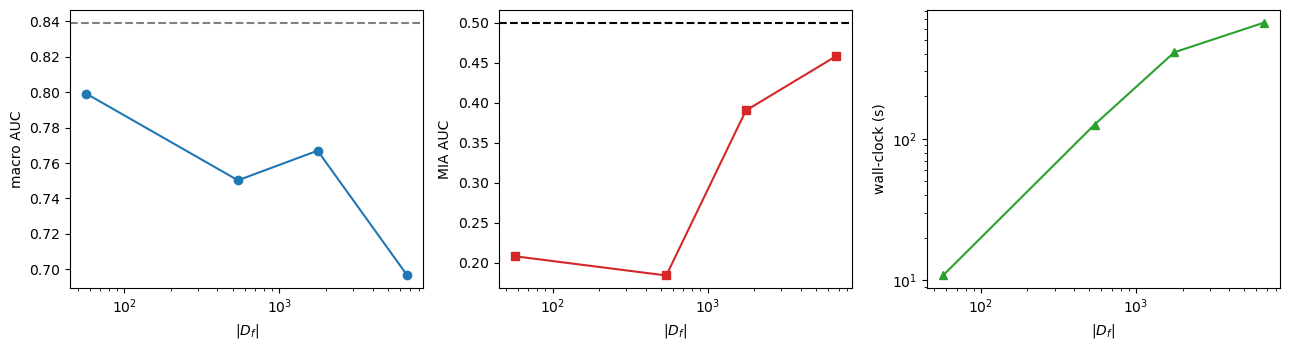

cost scaling exponent = 0.89 (Sec III-H predicts ~1.0 i.e. linear)
  [recorded] R_forget_scaling


In [35]:
SCALE_CSV = f"{RSTATS}/forget_scaling.csv"
rows = pd.read_csv(SCALE_CSV).to_dict("records") if os.path.exists(SCALE_CSV) else []
done_np = {r["n_patients"] for r in rows}

for npat in [28, 125, 500, 2000]:            # ~57, 250, 1000, 4000 images
    if npat in done_np: continue
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, n_patients=npat,
                                                seed=42, verbose=False)
    old_n = CFG["N_RETAIN_SUB"]
    CFG["N_RETAIN_SUB"] = min(4*len(f_idx), 8000)      # hold forget:retain ~= 1:4
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=42)
    print(f"\n--- {npat} patients | |Df|={len(f_idx)} | retain={len(r_sub)} ---")
    m = fresh_model(); t0 = time.time()
    m, _ = hybrid_unlearning(m, ld, f_idx, binary_labels=True); wall = time.time()-t0
    v = verify_baseline_relative(base_model, m, f_idx, r_sub)
    rows.append(dict(n_patients=npat, n_forget=len(f_idx), n_retain=len(r_sub),
                     wall_s=wall, macro_auc=macro_auc(m, desc=f"scale{npat}"),
                     mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
    CFG["N_RETAIN_SUB"] = old_n
    pd.DataFrame(rows).to_csv(SCALE_CSV, index=False)
    del m; torch.cuda.empty_cache()

SCALE = pd.DataFrame(rows).sort_values("n_forget")
display(SCALE[["n_forget","macro_auc","delta_forget_loss","mia_auc","wall_s"]]
        .style.format({"macro_auc":"{:.4f}","delta_forget_loss":"{:+.4f}",
                       "mia_auc":"{:.3f}","wall_s":"{:.0f}"}))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].semilogx(SCALE.n_forget, SCALE.macro_auc, "o-")
ax[0].axhline(MACRO_BEFORE, ls="--", c="gray"); ax[0].set_ylabel("macro AUC")
ax[1].semilogx(SCALE.n_forget, SCALE.mia_auc, "s-", color="tab:red")
ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_ylabel("MIA AUC")
ax[2].loglog(SCALE.n_forget, SCALE.wall_s, "^-", color="tab:green")
ax[2].set_ylabel("wall-clock (s)")
for a in ax: a.set_xlabel(r"$|D_f|$")
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig8_forget_scaling.png", dpi=200); plt.show()

sl = np.polyfit(np.log(SCALE.n_forget), np.log(SCALE.wall_s), 1)[0]
print(f"cost scaling exponent = {sl:.2f} (Sec III-H predicts ~1.0 i.e. linear)")
record("R_forget_scaling", SCALE[["n_forget","macro_auc","mia_auc"]].to_dict("records"))

## `[SKIP]` R13 — Second dataset

Deferred. Read the notes; don't run until everything above is written up.

In [36]:
# CheXpert:   https://stanfordmlgroup.github.io/competitions/chexpert/
# MIMIC-CXR:  https://physionet.org/content/mimic-cxr-jpg/  (credentialed access)
#
# Porting checklist:
#   1. CheXpert has 14 observations with UNCERTAIN (-1) labels. Pick a policy
#      (U-Zeros / U-Ones / U-MultiClass) and state it -- it materially moves AUC.
#   2. Patient IDs are in the path (patient00001/study1/view1_frontal.jpg); parse
#      them for build_patient_forget_set, and use the OFFICIAL patient-wise split.
#   3. Keep every unlearning hyperparameter identical so the comparison is clean.
#      The claim to test is that the confound and over-correction findings replicate,
#      not that the AUC matches.
#
# Once a CheXpert checkpoint exists, the entire study reruns unchanged:
#     CFG["CHECKPOINT"] = "chexpert_best.pth"
#     # re-run cells 5-15 and R1-R12
print("See markdown above. Budget ~12 h training + ~3 h to re-run the study.")

See markdown above. Budget ~12 h training + ~3 h to re-run the study.


# PART 4 — Export

## `[RUN]` E1 — LaTeX tables and proof status

Regenerates every table from the CSVs. Use `\input{}` in the paper — never retype a
number.

In [37]:
def write_table(fname, header, rows, colspec):
    with open(f"{CFG['OUT']}/tables/{fname}", "w") as f:
        f.write("\\begin{tabular}{" + colspec + "}\n\\toprule\n")
        f.write(" & ".join(f"\\textbf{{{h}}}" for h in header) + "\\\\\n\\midrule\n")
        for r in rows:
            f.write(" & ".join(str(x) for x in r) + "\\\\\n")
        f.write("\\bottomrule\n\\end{tabular}\n")
    print("  wrote", fname)

# Table: baselines
write_table("baselines.tex",
    ["Method","Val AUC",r"$\Delta\mathcal{L}_f$",r"$\Delta\mathcal{L}_r$","MIA AUC","Time"],
    [[n.replace("_"," "), f"{r['macro_auc_after']:.4f}",
      f"{r['delta_forget_loss']:+.4f}", f"{r['delta_retain_loss']:+.4f}",
      f"{r['mia_auc']:.3f}", f"{r['wall_clock_s']:.0f}\\,s"]
     for n, r in RESULTS_DF.iterrows()],
    "lccccc")

# Table: noise calibration
write_table("noise_calibration.tex",
    ["Clipping regime", r"$\Delta_2$", r"$\epsilon$ at $\sigma{=}10^{-4}$", r"$\sigma$ for $\epsilon{=}1$"],
    [[r["regime"], f"${r['delta2']:.2e}$", f"{r['eps_at_sigma']:.2f}",
      f"${r['sigma_for_eps1']:.2e}$"] for _, r in calib.iterrows()],
    "lccc")

# Table: pre/post verification (replaces the old Table VII)
write_table("verification.tex",
    ["Method",r"$\mathcal{L}_f$ pre",r"$\mathcal{L}_f$ post",r"$\Delta\mathcal{L}_f$",
     r"$\Delta\mathcal{L}_r$","MIA"],
    [[n.replace("_"," "), f"{r['forget_loss_before']:.4f}", f"{r['forget_loss_after']:.4f}",
      f"{r['delta_forget_loss']:+.4f}", f"{r['delta_retain_loss']:+.4f}", f"{r['mia_auc']:.3f}"]
     for n, r in RESULTS_DF.iterrows()],
    "lccccc")

CLAIMS = {
 "C1_patient_forget_set":"Forget set patient-disjoint, wholly in train partition",
 "C2_post_unlearn_auc":"Macro AUC after unlearning",
 "C3_pre_unlearn_baseline":"Table VII is forgetting, not subset composition",
 "C4_influence_method_runs":"Influence-weighted correction implemented and executed",
 "C5_influence_ablation":"Influence weighting beats uniform ascent",
 "C6_estimator_agreement":"Grad-norm and loss proxies agree",
 "C7_mia":"Forget samples indistinguishable from unseen",
 "C8_oracle":"Close to retrain oracle, not over-corrected",
 "C9_perclass_damage":"NOVELTY 1 — damage vs class prevalence",
 "C10_sequential":"NOVELTY 2 — repeated deletion trajectory",
 "C11_noise_calibration":"NOVELTY 3 — privacy-utility frontier",
 "C12_patientwise_split":"Headline AUC on official patient-wise split",
}
lines = ["# Proof status\n"]
for cid, desc in CLAIMS.items():
    done = cid in MANIFEST
    lines.append(f"- [{'x' if done else ' '}] **{cid}** — {desc}")
    if done:
        for e in MANIFEST[cid]:
            lines.append(f"    - {e['value']}")
open(f"{CFG['OUT']}/PROOF_STATUS.md","w").write("\n".join(lines))

done = sum(c in MANIFEST for c in CLAIMS)
print(f"\n{done}/{len(CLAIMS)} claims backed by evidence")
for c, d in CLAIMS.items():
    if c not in MANIFEST:
        print(f"  STILL OPEN: {c} — {d}")
print(f"\nArtifacts in {CFG['OUT']}/  — \\input the tables, do not retype numbers.")

  wrote baselines.tex
  wrote noise_calibration.tex
  wrote verification.tex

10/12 claims backed by evidence
  STILL OPEN: C10_sequential — NOVELTY 2 — repeated deletion trajectory
  STILL OPEN: C12_patientwise_split — Headline AUC on official patient-wise split

Artifacts in proofs/  — \input the tables, do not retype numbers.


In [38]:
# ============================================================================
# R14 — External-validity WITHOUT a second dataset
#
# You can't download CheXpert/MIMIC, but ChestX-ray14's metadata already encodes
# real acquisition and population shifts. Data_Entry_2017.csv carries:
#     View Position   (AP vs PA)  <- the strongest shift; AP is portable/bedside,
#                                    sicker patients, different geometry entirely
#     Patient Gender  (M / F)
#     Patient Age
#
# Training on one subgroup and evaluating on the other is a genuine covariate
# shift. It is NOT a substitute for a second dataset -- say so in the paper --
# but it does test whether the two findings that matter (the confound and the
# over-correction ordering) are stable across distributions, which is the actual
# question behind "only one dataset".
#
# Cost: ~25 min. No downloads.
# ============================================================================

meta = dataset.data
print("available metadata columns:", [c for c in meta.columns][:8])

SHIFT_COL, GROUP_A, GROUP_B = "View Position", "PA", "AP"

val_set = set(int(i) for i in val_indices)
col = meta[SHIFT_COL].values
grp = {g: [i for i in val_set if col[i] == g] for g in (GROUP_A, GROUP_B)}
print(f"\nvalidation split by {SHIFT_COL}:")
for g, idxs in grp.items():
    pos_rate = dataset.labels.iloc[idxs].mean().drop("No Finding").mean()
    print(f"  {g}: {len(idxs)} images, mean pathology rate {pos_rate:.3f}")

def subgroup_loader(idxs):
    return DataLoader(TransformedSubset(dataset, idxs, transform_val),
                      batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

rows = []
for name in ["original"] + [n for n in RESULTS]:
    m = base_model if name == "original" else (MODELS.get(name) or load_saved_model(name))
    if m is None:
        continue
    r = {"method": name}
    for g, idxs in grp.items():
        a = per_class_auc(m, subgroup_loader(idxs), desc=f"{name}/{g}")
        r[f"auc_{g}"] = float(np.mean(list(a.values())))
    r["shift_gap"] = r[f"auc_{GROUP_A}"] - r[f"auc_{GROUP_B}"]
    rows.append(r)
    print(f"  {name:22s} {GROUP_A} {r[f'auc_{GROUP_A}']:.4f} | "
          f"{GROUP_B} {r[f'auc_{GROUP_B}']:.4f} | gap {r['shift_gap']:+.4f}")

SHIFT = pd.DataFrame(rows)
SHIFT.to_csv(f"{RSTATS}/subgroup_shift.csv", index=False)

# Does unlearning damage transfer across the shift, or is it distribution-specific?
base = SHIFT[SHIFT.method == "original"].iloc[0]
SHIFT["damage_PA"] = SHIFT[f"auc_{GROUP_A}"] - base[f"auc_{GROUP_A}"]
SHIFT["damage_AP"] = SHIFT[f"auc_{GROUP_B}"] - base[f"auc_{GROUP_B}"]
sub = SHIFT[SHIFT.method != "original"]
rho, p = spearmanr(sub["damage_PA"], sub["damage_AP"])
print(f"\nSpearman(damage on {GROUP_A}, damage on {GROUP_B}) = {rho:.3f} (p={p:.4f})")
print("High rho => the over-correction ordering is stable across a real")
print("           acquisition shift, which is the claim a second dataset tests.")
display(SHIFT.style.format({c: "{:.4f}" for c in SHIFT.columns if c != "method"}))
record("R_subgroup_shift", dict(shift=SHIFT_COL, spearman=float(rho), p=float(p)))

available metadata columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width']

validation split by View Position:
  PA: 13487 images, mean pathology rate 0.045
  AP: 8937 images, mean pathology rate 0.060


original/PA:   0%|          | 0/422 [00:00<?, ?it/s]

original/AP:   0%|          | 0/280 [00:00<?, ?it/s]

  original               PA 0.8333 | AP 0.8209 | gap +0.0124


influence_weighted/PA:   0%|          | 0/422 [00:00<?, ?it/s]

influence_weighted/AP:   0%|          | 0/280 [00:00<?, ?it/s]

... (20 outputs left out)

ssd_F24/AP:   0%|          | 0/280 [00:00<?, ?it/s]

  ssd_F24                PA 0.8332 | AP 0.8208 | gap +0.0125

Spearman(damage on PA, damage on AP) = 1.000 (p=0.0000)
High rho => the over-correction ordering is stable across a real
           acquisition shift, which is the claim a second dataset tests.


,method,auc_PA,auc_AP,shift_gap,damage_PA,damage_AP
0,original,0.8333,0.8209,0.0124,0.0000,0.0000
1,influence_weighted,0.6587,0.6634,-0.0047,-0.1746,-0.1575
2,neggrad_ablation,0.5534,0.6195,-0.0661,-0.2799,-0.2014
3,hybrid_bernoulli,0.8042,0.7944,0.0098,-0.0290,-0.0264
4,hybrid_uniform,0.7934,0.7906,0.0028,-0.0398,-0.0303
5,finetune_retain,0.8158,0.8059,0.0100,-0.0174,-0.0150
6,fisher_scrubbing_G20,0.8333,0.8208,0.0124,-0.0000,-0.0000
7,scrub_K23,0.8309,0.8195,0.0114,-0.0023,-0.0014
8,ssd_F24,0.8332,0.8208,0.0125,-0.0000,-0.0001


  [recorded] R_subgroup_shift
